# YZ50 — Week 10: Reproducing GPT-2 (124M)

- **From Week 8 to GPT-2.** My Week 8 GPT was a 209,729-parameter character-level model with a context of 32 characters. GPT-2 keeps the same **decoder-only** design: token and position embeddings, pre-normalized Transformer blocks with causal self-attention and a feedforward network, a final LayerNorm, and a projection to vocabulary logits.

- **Scale.** GPT-2 small has **12 blocks, 12 heads, 768 channels, a 1,024-token context**, and the **50,257-token byte-level BPE vocabulary** whose construction I followed in Week 9. Together this gives about **124 million parameters**.

- **Pretrained weights.** OpenAI released the trained GPT-2 parameters, and Hugging Face Transformers distributes them as PyTorch tensors. Loading them gives a reference model whose behavior is known.

- **Verification against a reference.** If my implementation computes the same function, the same weights must give the **same logits** as the Hugging Face model for the same input. Plausible generated text is not enough evidence; matching numbers are.

- **Sampling.** Generation repeats next-token prediction. **Top-k sampling** draws the next token only from the k most probable candidates.

- **Training from scratch.** A randomly initialized model should start close to the loss of a uniform guess, \(\ln 50257\approx 10.82\). A correct model and optimizer should then be able to **memorize one fixed batch**.

In this week, I follow the first hour of Karpathy's GPT-2 reproduction lecture. I inspect the pretrained GPT-2 (124M) weights and its position embeddings, rewrite my Week 8 GPT as a GPT-2 module, load the Hugging Face weights into it, and check that both models produce the same logits. I then write a top-k sampling loop, generate English and Turkish text, connect GPT-2's Turkish token counts with my Week 9 measurements, and finally measure the initial loss of a randomly initialized GPT-2 and overfit a single batch on the RTX 3060 Laptop GPU.

In [1]:
from pathlib import Path
import gc
import math
import time
from collections import Counter
from dataclasses import dataclass
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.nn import functional as F
import tiktoken
import transformers
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
from IPython.display import display, Markdown

seed = 1337
torch.manual_seed(seed)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
data_dir = Path.cwd()
if not (data_dir / 'input.txt').exists():
    data_dir = data_dir / 'week-10'
print('PyTorch:', torch.__version__, '| transformers:', transformers.__version__, '| tiktoken:', tiktoken.__version__)
print('device:', device)
if device == 'cuda':
    props = torch.cuda.get_device_properties(0)
    print(f'GPU: {props.name} | memory: {props.total_memory / 2**30:.1f} GiB | compute capability: {props.major}.{props.minor}')

PyTorch: 2.14.0+cu126 | transformers: 4.57.1 | tiktoken: 0.14.0
device: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU | memory: 6.0 GiB | compute capability: 8.6


## Numerical Precision

Two implementations of the same function rarely agree **bit for bit**. Kernels add numbers in different orders, and floating-point addition is not associative, so each matrix multiplication carries a small rounding error. In float32 this error is about \(10^{-7}\) relative to the values involved. It accumulates through 12 blocks, but it should stay far below the size of the logits.

On Ampere GPUs such as the RTX 3060, PyTorch may run float32 matrix multiplications in **TF32**, which keeps only 10 mantissa bits (a relative precision of about \(10^{-3}\)). This is a reasonable trade for training speed, but in a reference comparison it would produce differences large enough to hide a real implementation error. I therefore disable TF32 for the whole notebook, and every model here runs in float32.

In [2]:
# full float32 matrix multiplications: no TF32 on Ampere GPUs
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.set_float32_matmul_precision('highest')
print('TF32 matmul:', torch.backends.cuda.matmul.allow_tf32, '| TF32 cuDNN:', torch.backends.cudnn.allow_tf32,
      '| float32 matmul precision:', torch.get_float32_matmul_precision())

TF32 matmul: False | TF32 cuDNN: False | float32 matmul precision: highest


# 1. Hazır GPT-2'yi incele. Hugging Face'ten GPT-2 (124M) ağırlıklarını yükle. Her ağırlığın adını ve boyutunu yazdır, toplam parametre sayısını hesapla. Pozisyon embedding'lerini (wpe) çiz: ne görüyorsun, kendi cümlelerinle yaz.

## 1. Inspect the Pretrained GPT-2

A model has two separate parts:

- **Architecture:** the sequence of operations, defined by code and a small configuration (number of layers, heads, channels, vocabulary size, context length).
- **Parameters:** the numbers those operations use. **Pretrained weights** are parameter values that were already learned by training on a large corpus; OpenAI trained GPT-2 on its WebText dataset.

The same architecture with random parameters produces noise; with the pretrained parameters it produces English text. Hugging Face Transformers provides both a PyTorch implementation of the architecture and the converted weights. Because that implementation is widely used and tested, it is a useful **reference**: if my own code produces the same outputs from the same weights, my architecture is correct.

`openai-community/gpt2` is the smallest of the four GPT-2 sizes, the 124M model. The weights are downloaded once into the Hugging Face cache in my home directory, not into this repository. I load the model with `attn_implementation="eager"`, so the reference computes attention with explicit matrix multiplications and softmax, as my own implementation will, rather than with a fused kernel. `eval()` disables dropout.

In [3]:
model_hf = GPT2LMHeadModel.from_pretrained('openai-community/gpt2', attn_implementation='eager')
model_hf.eval()
sd_hf = model_hf.state_dict()
config_hf = model_hf.config
print(type(model_hf).__name__, '| attention implementation:', config_hf._attn_implementation,
      '| dtype:', next(model_hf.parameters()).dtype, '| training mode:', model_hf.training)

GPT2LMHeadModel | attention implementation: eager | dtype: torch.float32 | training mode: False


### The Configuration

The configuration fixes every shape in the model:

- `vocab_size = 50257`: 256 byte tokens, 50,000 BPE merges, and the special token `<|endoftext|>` (Week 9).
- `n_positions = 1024`: the context length, which is also the number of rows in the position embedding table.
- `n_layer = 12`, `n_head = 12`, `n_embd = 768`: twelve blocks; each head works with \(768/12=64\) channels.

The configuration also stores the training-time dropout probabilities and the activation function name `gelu_new`; both matter in Task 2.

In [4]:
print('vocab_size :', config_hf.vocab_size)
print('n_positions:', config_hf.n_positions)
print('n_layer    :', config_hf.n_layer)
print('n_head     :', config_hf.n_head)
print('n_embd     :', config_hf.n_embd, '-> head size', config_hf.n_embd // config_hf.n_head)
print('activation :', config_hf.activation_function, '| layer_norm_epsilon:', config_hf.layer_norm_epsilon)
print('dropout    : embeddings', config_hf.embd_pdrop, '| attention', config_hf.attn_pdrop, '| residual', config_hf.resid_pdrop)
print('tie_word_embeddings:', config_hf.tie_word_embeddings)

assert (config_hf.vocab_size, config_hf.n_positions, config_hf.n_layer, config_hf.n_head, config_hf.n_embd) == (50257, 1024, 12, 12, 768)
assert config_hf.activation_function == 'gelu_new' and config_hf.tie_word_embeddings
print('Configuration checks passed.')

vocab_size : 50257
n_positions: 1024
n_layer    : 12
n_head     : 12
n_embd     : 768 -> head size 64
activation : gelu_new | layer_norm_epsilon: 1e-05
dropout    : embeddings 0.1 | attention 0.1 | residual 0.1
tie_word_embeddings: True
Configuration checks passed.


### Every Weight and Its Shape

The **state dict** maps parameter names to tensors. Names follow the module hierarchy: `transformer.h.5.attn.c_attn.weight` is the query/key/value projection of block 5. Each of the 12 blocks has the same 12 tensors (two LayerNorms, the attention projections, the MLP projections), so the list below is long but regular.

In [5]:
for k, v in sd_hf.items():
    print(f"{k:38} {str(tuple(v.shape)):13} {v.numel():>12,}")
print('state-dict entries:', len(sd_hf))

transformer.wte.weight                 (50257, 768)    38,597,376
transformer.wpe.weight                 (1024, 768)        786,432
transformer.h.0.ln_1.weight            (768,)                 768
transformer.h.0.ln_1.bias              (768,)                 768
transformer.h.0.attn.c_attn.weight     (768, 2304)      1,769,472
transformer.h.0.attn.c_attn.bias       (2304,)              2,304
transformer.h.0.attn.c_proj.weight     (768, 768)         589,824
transformer.h.0.attn.c_proj.bias       (768,)                 768
transformer.h.0.ln_2.weight            (768,)                 768
transformer.h.0.ln_2.bias              (768,)                 768
transformer.h.0.mlp.c_fc.weight        (768, 3072)      2,359,296
transformer.h.0.mlp.c_fc.bias          (3072,)              3,072
transformer.h.0.mlp.c_proj.weight      (3072, 768)      2,359,296
transformer.h.0.mlp.c_proj.bias        (768,)                 768
transformer.h.1.ln_1.weight            (768,)                 768
transforme

### Counting Parameters

`lm_head.weight` and `transformer.wte.weight` are the **same tensor**: GPT-2 uses the token embedding matrix again as the output projection (weight tying, Task 2). The state dict lists the shared tensor under both names, so summing its entries counts \(50257\times768 = 38{,}597{,}376\) numbers twice. `model.parameters()` yields every parameter object once, which gives the number of **unique trainable parameters**.

In [6]:
n_unique = sum(p.numel() for p in model_hf.parameters())
n_state_dict = sum(v.numel() for v in sd_hf.values())
n_tied = sd_hf['lm_head.weight'].numel()
print(f'unique trainable parameters:        {n_unique:>12,}')
print(f'sum over state-dict entries:        {n_state_dict:>12,}')
print(f'difference (shared wte / lm_head):  {n_state_dict - n_unique:>12,}')
print('parameter tensors:', len(list(model_hf.parameters())), '| state-dict entries:', len(sd_hf))

assert n_unique == 124_439_808
assert model_hf.lm_head.weight.data_ptr() == model_hf.transformer.wte.weight.data_ptr() # same storage
assert n_state_dict - n_unique == n_tied == 50257 * 768
print('Parameter-count and weight-sharing checks passed.')

unique trainable parameters:         124,439,808
sum over state-dict entries:         163,037,184
difference (shared wte / lm_head):    38,597,376
parameter tensors: 148 | state-dict entries: 149
Parameter-count and weight-sharing checks passed.


In [7]:
def parameter_group(name):
    if '.wte.' in name: return 'token embedding `wte` (shared with `lm_head`)'
    if '.wpe.' in name: return 'position embedding `wpe`'
    if '.attn.' in name: return 'attention `c_attn`, `c_proj`'
    if '.mlp.' in name: return 'MLP `c_fc`, `c_proj`'
    return 'LayerNorm `ln_1`, `ln_2`, `ln_f`'

group_counts = Counter()
for name, p in model_hf.named_parameters(): # shared parameters appear once
    group_counts[parameter_group(name)] += p.numel()
assert sum(group_counts.values()) == n_unique

lines = ['| Parameter group | Parameters | Share |', '|---|---:|---:|']
for group, count in group_counts.most_common():
    lines.append(f'| {group} | {count:,} | {count / n_unique:.1%} |')
lines.append(f'| **total (unique)** | **{n_unique:,}** | 100% |')
display(Markdown('\n'.join(lines)))

| Parameter group | Parameters | Share |
|---|---:|---:|
| MLP `c_fc`, `c_proj` | 56,669,184 | 45.5% |
| token embedding `wte` (shared with `lm_head`) | 38,597,376 | 31.0% |
| attention `c_attn`, `c_proj` | 28,348,416 | 22.8% |
| position embedding `wpe` | 786,432 | 0.6% |
| LayerNorm `ln_1`, `ln_2`, `ln_f` | 38,400 | 0.0% |
| **total (unique)** | **124,439,808** | 100% |

GPT-2 small has **124,439,808** unique parameters, as the assertion requires; summing the 149 state-dict entries gives 163,037,184 because the 38,597,376 numbers of the shared `wte`/`lm_head` matrix are counted twice.

Most parameters sit in the **MLPs (45.5%)**, then the **token embedding (31.0%)** and **attention (22.8%)**. The position table (0.6%) and the 25 LayerNorms (38,400 parameters) are small. In my Week 8 model, the embedding table and `lm_head` were tiny because the vocabulary had 65 characters; with 50,257 BPE tokens, the vocabulary matrix alone is almost a third of GPT-2. Without weight tying, a second copy would make the two vocabulary matrices together 47% of the model.

### Positional Embeddings

Attention compares feature vectors and has no built-in notion of order (Week 8). GPT-2 therefore adds a **position vector** to every token embedding: `wpe` is an `nn.Embedding(1024, 768)`, and row \(t\) is added at position \(t\).

The original Transformer used **fixed sinusoids**,

\[
PE_{t,2i}=\sin\!\left(\frac{t}{10000^{2i/d}}\right),\qquad
PE_{t,2i+1}=\cos\!\left(\frac{t}{10000^{2i/d}}\right).
\]

GPT-2 instead uses **learned** position embeddings, as my Week 8 GPT did: the rows start as random numbers and are trained by gradient descent like every other weight. Any structure in them was found by training, not written by hand.

I look at the table in four ways: the whole matrix, three individual channels across positions (the lecture plots channels 150, 200, and 250), cosine similarity between positions, and the norm of each position vector.

wpe: (1024, 768) | mean -0.0007 | std 0.1227 | min -4.538 | max 4.065


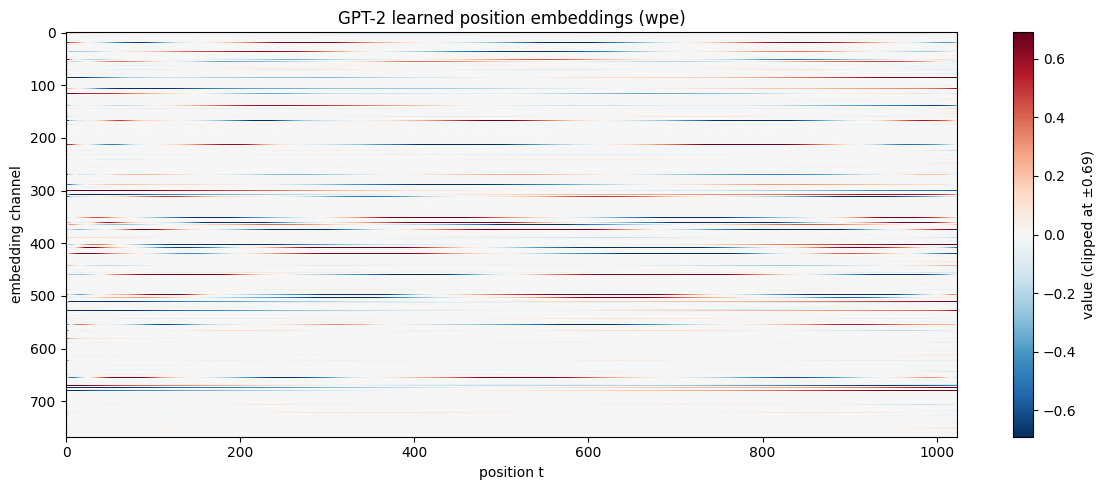

In [8]:
wpe = sd_hf['transformer.wpe.weight'].detach().float().cpu() # (1024, 768): one row per position
print('wpe:', tuple(wpe.shape), f'| mean {wpe.mean():.4f} | std {wpe.std():.4f} | min {wpe.min():.3f} | max {wpe.max():.3f}')

lim = wpe.abs().quantile(0.99).item() # symmetric color range, ignoring the most extreme 1%
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(wpe.T, aspect='auto', cmap='RdBu_r', vmin=-lim, vmax=lim, interpolation='nearest')
ax.set_title('GPT-2 learned position embeddings (wpe)')
ax.set_xlabel('position t')
ax.set_ylabel('embedding channel')
fig.colorbar(im, ax=ax, label=f'value (clipped at ±{lim:.2f})')
plt.tight_layout()
plt.show()

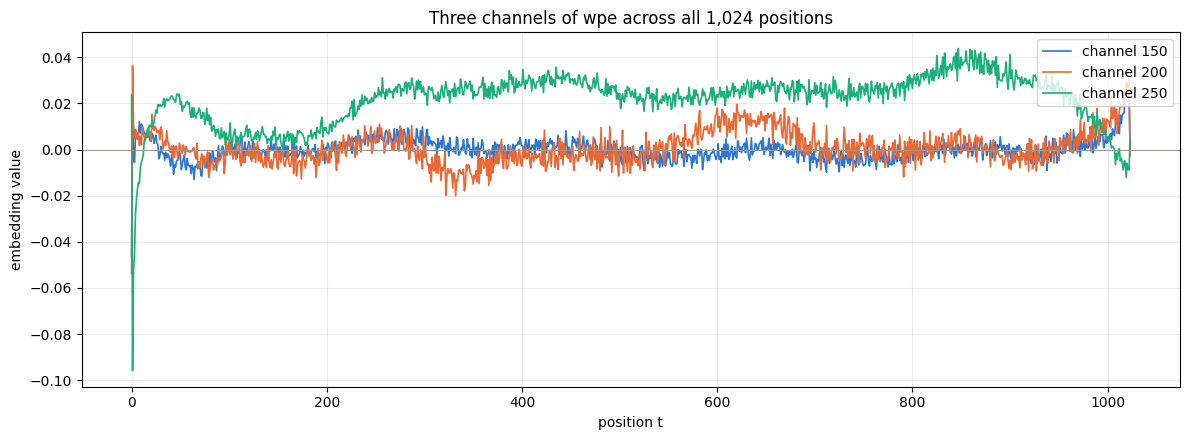

In [9]:
channels = [150, 200, 250]
colors = ['#2a78d6', '#eb6834', '#1baf7a']
fig, ax = plt.subplots(figsize=(12, 4.5))
for ch, color in zip(channels, colors):
    ax.plot(wpe[:, ch], color=color, linewidth=1.2, label=f'channel {ch}')
ax.axhline(0, color='#9a9a94', linewidth=0.8)
ax.set_title('Three channels of wpe across all 1,024 positions')
ax.set_xlabel('position t')
ax.set_ylabel('embedding value')
ax.grid(alpha=0.25)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

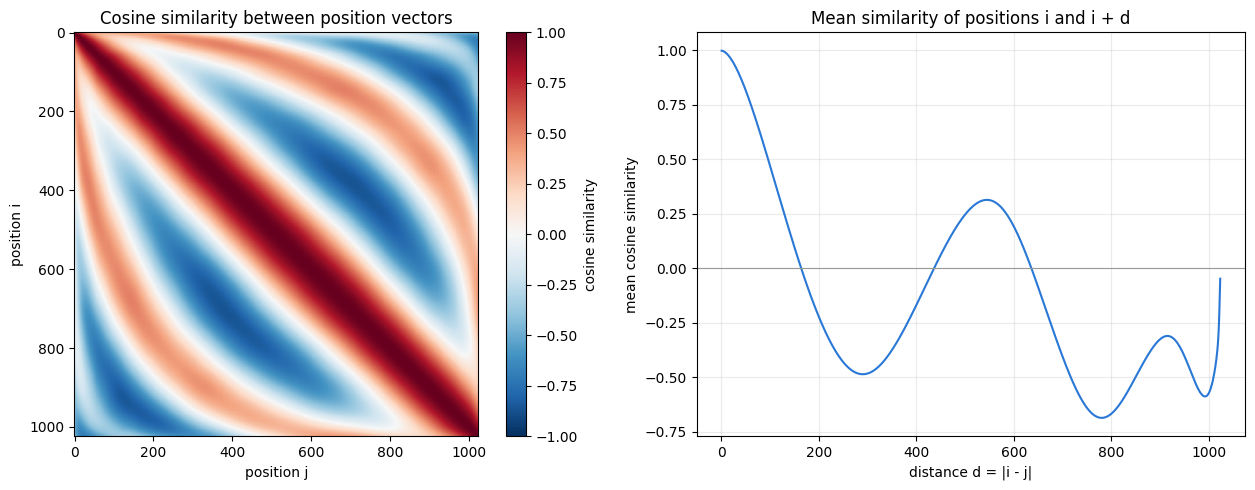

distance    1: mean cosine similarity +0.997
distance    2: mean cosine similarity +0.997
distance    5: mean cosine similarity +0.995
distance   10: mean cosine similarity +0.987
distance   50: mean cosine similarity +0.818
distance  100: mean cosine similarity +0.471
distance  200: mean cosine similarity -0.222
distance  500: mean cosine similarity +0.246
distance 1000: mean cosine similarity -0.571


In [10]:
wpe_unit = F.normalize(wpe, dim=1)
sim = wpe_unit @ wpe_unit.T # (1024, 1024) cosine similarity between position vectors
offsets = torch.arange(1, 1024)
sim_by_offset = torch.stack([sim.diagonal(int(d)).mean() for d in offsets]) # mean over all pairs |i-j| = d

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
im = axes[0].imshow(sim, cmap='RdBu_r', vmin=-1, vmax=1, interpolation='nearest')
axes[0].set_title('Cosine similarity between position vectors')
axes[0].set_xlabel('position j')
axes[0].set_ylabel('position i')
fig.colorbar(im, ax=axes[0], label='cosine similarity')
axes[1].plot(offsets, sim_by_offset, color='#2a78d6', linewidth=1.5)
axes[1].axhline(0, color='#9a9a94', linewidth=0.8)
axes[1].set_title('Mean similarity of positions i and i + d')
axes[1].set_xlabel('distance d = |i - j|')
axes[1].set_ylabel('mean cosine similarity')
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

for d in [1, 2, 5, 10, 50, 100, 200, 500, 1000]:
    print(f'distance {d:4d}: mean cosine similarity {sim_by_offset[d - 1]:+.3f}')

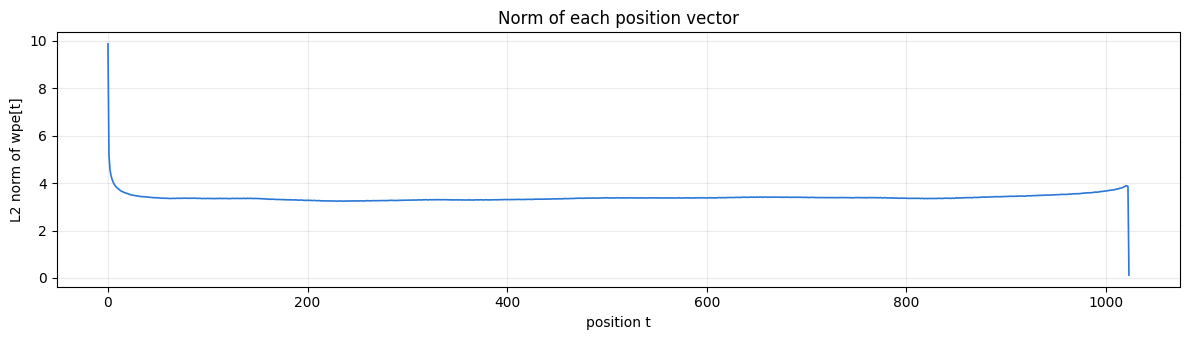

largest norms: [(0, 9.88), (1, 5.19), (2, 4.59), (3, 4.34), (4, 4.18)]
median norm: 3.37
last positions: [(1019, 3.86), (1020, 3.89), (1021, 3.88), (1022, 3.86), (1023, 0.12)]
channel 150: std 0.0048 | mean |wpe[t+1] - wpe[t]| 0.0032
channel 200: std 0.0073 | mean |wpe[t+1] - wpe[t]| 0.0046
channel 250: std 0.0111 | mean |wpe[t+1] - wpe[t]| 0.0031


In [11]:
norms = wpe.norm(dim=1)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(norms, color='#2a78d6', linewidth=1.2)
ax.set_title('Norm of each position vector')
ax.set_xlabel('position t')
ax.set_ylabel('L2 norm of wpe[t]')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print('largest norms:', [(int(t), round(norms[t].item(), 2)) for t in norms.argsort(descending=True)[:5]])
print(f'median norm: {norms.median():.2f}')
print('last positions:', [(t, round(norms[t].item(), 2)) for t in range(1019, 1024)])
# roughness: mean absolute step between neighbouring positions, relative to the channel's spread
for ch in channels:
    col = wpe[:, ch]
    print(f'channel {ch}: std {col.std():.4f} | mean |wpe[t+1] - wpe[t]| {(col[1:] - col[:-1]).abs().mean():.4f}')

### What I See in the Position Embeddings

- **The table is organized by channel.** The heatmap consists of horizontal bands: a channel tends to keep its sign and size over long ranges of positions, and only a minority of channels carry large values. The table's standard deviation is 0.12, but a few entries reach −4.5 and 4.1, far outside the clipped color range.
- **Individual channels combine slow trends with noise.** Channels 150, 200, and 250 are low-variance channels (standard deviations 0.005 to 0.011, against 0.12 for the whole table). Each curve drifts slowly over hundreds of positions, and on top of that it is jagged from one position to the next. For channels 150 and 200, the mean step between neighbouring positions (0.0032 and 0.0046) is close to the channel's standard deviation (0.0048 and 0.0073), so the noise is a large part of their variation. Channel 250 (step 0.0031, standard deviation 0.0111) follows a smoother trend. In the lecture, Karpathy reads this jaggedness as a sign that the model was not trained to convergence. That is a plausible interpretation, but the weights alone cannot confirm it.
- **Nearby positions are similar, and similarity oscillates with distance.** Neighbouring positions have a mean cosine similarity of 0.997, still 0.987 at distance 10, then 0.818 at distance 50, 0.471 at 100, and −0.222 at 200. Beyond that, the mean similarity rises and falls again (+0.246 at 500, −0.571 at 1000). The similarity matrix shows a bright diagonal band surrounded by alternating curved arcs. This wave-like pattern resembles the structure of sinusoidal encodings, although training was never told to produce sinusoids. The arcs bend toward the corners, so the "wavelength" is not the same at every position.
- **The two ends are irregular.** Position 0 has a norm of 9.88, almost three times the median of 3.37, and the norms fall over the first positions (5.19, 4.59, 4.34, 4.18 for positions 1 to 4). Position 0 is special in every sequence: the first token is predicted without any context. The norms rise slightly toward the end of the table (about 3.9 for positions 1019 to 1022), and then the **last position, 1023, has a norm of only 0.12**. Such a small vector looks as if position 1023 received few or no useful gradient updates during OpenAI's training, but I cannot determine the cause from the weights.

Overall, the learned table is far from random: position is encoded smoothly, with a structure reminiscent of sinusoids, plus noise and edge effects that a hand-designed encoding would not have.

# 2. GPT-2'yi kendin yaz ve ağırlıkları yükle. Hafta 8'deki GPT'nden yola çıkarak GPT-2 modülünü yaz. Hugging Face ağırlıklarını kendi modeline yükle. Aynı girdi için kendi modelinin logits'inin Hugging Face modelininkiyle aynı çıktığını göster. Hafta 8'deki GPT'nden farklarını madde madde yaz, örneğin aktivasyon fonksiyonu ve q, k, v'nin tek katmanda hesaplanması. Bazı ağırlıkları yüklerken neden transpoze etmen gerektiğini de yaz.

## 2. From My Week 8 GPT to GPT-2

The table compares the **reference GPT** of my Week 8 notebook (the model trained on Tiny Shakespeare with `n_embd=64, n_head=4, n_layer=4, block_size=32`) with GPT-2 small. The Week 8 values come from that notebook's code and saved outputs.

| Property | Week 8 reference GPT | GPT-2 small |
|---|---|---|
| Tokens | characters | byte-level BPE (Week 9) |
| Vocabulary size | 65 (Shakespeare), 92 (Turkish) | 50,257 |
| Context length | 32 | 1,024 |
| Embedding dimension | 64 | 768 |
| Transformer blocks | 4 | 12 |
| Attention heads | 4 heads × 16 channels | 12 heads × 64 channels |
| Q, K, V projections | a separate `Head` module per head, each with its own `key`, `query`, `value` layers | **one** `c_attn` layer for all heads and all three roles: 768 → 2,304 |
| Q, K, V biases | none (`bias=False`) | yes |
| Attention output projection | `proj`, with bias | `c_proj`, with bias |
| Feedforward | 64 → 256 → 64, **ReLU** | 768 → 3,072 → 768, **GELU (tanh approximation)** |
| LayerNorm | pre-norm `ln1`, `ln2`, final `ln_f`; ε = 1e-5 | pre-norm `ln_1`, `ln_2`, final `ln_f`; ε = 1e-5 |
| Position embedding | learned, `nn.Embedding(32, 64)` | learned, `nn.Embedding(1024, 768)` |
| Output projection | `lm_head` with bias | `lm_head` without bias |
| Weight tying | no | `lm_head.weight` is `wte.weight` |
| Dropout | 0.0 (0.2 in the dropout run) | 0.1 during OpenAI's training; disabled for evaluation |
| Parameters | 209,729 | 124,439,808 |

**What stays the same** is the part I built step by step in Weeks 7 and 8:

- **Causal self-attention:** queries meet keys, scores are scaled by \(1/\sqrt{d_{head}}\), future positions are masked, softmax weights average the values.
- **Multi-head attention:** the channels are split across heads whose outputs are concatenated and projected.
- **Residual connections and pre-normalization:** `x = x + attn(ln_1(x))`, then `x = x + mlp(ln_2(x))`.
- **A position-wise feedforward network** with a 4× expansion.
- **Autoregressive prediction:** position \(t\) predicts token \(t+1\) from tokens \(\le t\), trained with cross-entropy.

The differences are mostly **scale** and a few **engineering choices** (fused projections, GELU, no output bias, weight tying). My module names follow Hugging Face's (`wte`, `wpe`, `h`, `ln_1`, `c_attn`, ...), so the two state dicts can be matched key by key.

### Configuration

A dataclass collects the five numbers that determine every shape. The defaults are GPT-2 small; smaller configurations are used for quick tests.

In [12]:
@dataclass
class GPTConfig:
    block_size: int = 1024 # max sequence length
    vocab_size: int = 50257 # 50,000 BPE merges + 256 bytes tokens + 1 <|endoftext|> token
    n_layer: int = 12 # number of layers
    n_head: int = 12 # number of heads
    n_embd: int = 768 # embedding dimension

print(GPTConfig())

GPTConfig(block_size=1024, vocab_size=50257, n_layer=12, n_head=12, n_embd=768)


### Causal Self-Attention with One Fused Projection

In Week 8, each `Head` had three bias-free linear layers, and `MultiHeadAttention` kept a list of heads. All of these layers read the **same input** `x`, so their weight matrices can be stacked into one larger matrix. GPT-2's `c_attn` maps \(C=768\) channels to \(3C=2304\) outputs: the first 768 are the queries of all heads, the next 768 the keys, and the last 768 the values.

The split into heads is a reshape. With \(n_{head}\) heads, each gets \(d_{head}=C/n_{head}\) channels:

**`(B,T,3C)` → split → three `(B,T,C)` → view `(B,T,n_head,d_head)` → transpose → `(B,n_head,T,d_head)`**

Treating the head dimension like a batch dimension, a single matrix multiplication computes all heads in parallel:

\[
\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_{head}}}+M\right)V,
\qquad
M_{t,j}=\begin{cases}0 & j\le t\\-\infty & j>t\end{cases}
\]

The causal mask \(M\) is the Week 7 trick: position \(t\) predicts token \(t+1\), so letting it see positions \(j>t\) would let it read the answer, and the model would learn nothing usable for generation. Splitting the channels across heads keeps the cost of multi-head attention equal to one full-width head while allowing different heads to learn different communication patterns. The concatenated head outputs are mixed by `c_proj`.

The triangular mask is a **non-persistent buffer** named `tril`, as in Week 8. It moves with the model to the GPU but is not part of the state dict, so it does not appear among the weights to load. I compute attention explicitly, with the same operations as Hugging Face's eager attention, so the comparison checks the formula rather than the choice of kernel.

In [13]:
class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        # key, query, value projections for all heads, but in a batch
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        # causal mask, not a learned weight and not saved in the state dict
        tril = torch.tril(torch.ones(config.block_size, config.block_size))
        self.register_buffer('tril', tril.view(1, 1, config.block_size, config.block_size), persistent=False)

    def forward(self, x):
        B, T, C = x.size() # batch size, sequence length, embedding dimensionality (n_embd)
        qkv = self.c_attn(x) # (B,T,3C)
        q, k, v = qkv.split(self.n_embd, dim=2) # each (B,T,C)
        # nh is "number of heads", hs is "head size", and C (number of channels) = nh * hs
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B,nh,T,hs)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B,nh,T,hs)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B,nh,T,hs)
        # attention (materializes the large (T,T) matrix for all the queries and keys)
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1))) # (B,nh,T,T)
        att = att.masked_fill(self.tril[:, :, :T, :T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        y = att @ v # (B,nh,T,T) @ (B,nh,T,hs) -> (B,nh,T,hs)
        y = y.transpose(1, 2).contiguous().view(B, T, C) # re-assemble all head outputs side by side
        # output projection
        y = self.c_proj(y)
        return y

The next cell traces the shapes on a small configuration with 32 channels and 4 heads.

In [14]:
torch.manual_seed(seed)
toy_config = GPTConfig(block_size=16, vocab_size=100, n_layer=2, n_head=4, n_embd=32)
attn = CausalSelfAttention(toy_config)
x = torch.randn(2, 8, toy_config.n_embd) # (B,T,C)

qkv = attn.c_attn(x)
q, k, v = qkv.split(toy_config.n_embd, dim=2)
hs = toy_config.n_embd // toy_config.n_head
print('x        ', tuple(x.shape))
print('c_attn(x)', tuple(qkv.shape), '| c_attn.weight', tuple(attn.c_attn.weight.shape))
print('q, k, v  ', tuple(q.shape), tuple(k.shape), tuple(v.shape))
print('q by head', tuple(q.view(2, 8, toy_config.n_head, hs).transpose(1, 2).shape), '(B, n_head, T, head size)')
print('output   ', tuple(attn(x).shape))

x         (2, 8, 32)
c_attn(x) (2, 8, 96) | c_attn.weight (96, 32)
q, k, v   (2, 8, 32) (2, 8, 32) (2, 8, 32)
q by head (2, 4, 8, 8) (B, n_head, T, head size)
output    (2, 8, 32)


#### Is the Fused Layer Really the Week 8 Computation?

To check the claim that one `c_attn` layer is the same as separate per-head layers, `week8_style_attention` slices the fused weight into one query, key, and value matrix per head and runs the Week 8 `Head` loop: unbatched scores, scaling by the head size, the triangular mask, softmax, and concatenation. The two results must agree. The cell also repeats the Week 8 causal check: changing the inputs at positions 4 and later must not change the outputs at positions 0 to 3.

In [15]:
def week8_style_attention(attn, x):
    # one Week 8 Head per slice of the fused c_attn weight
    B, T, C = x.shape
    hs = C // attn.n_head
    W, b = attn.c_attn.weight, attn.c_attn.bias # (3C, C), (3C,): rows 0:C queries, C:2C keys, 2C:3C values
    tril = torch.tril(torch.ones(T, T))
    outs = []
    for h in range(attn.n_head):
        rows = slice(h * hs, (h + 1) * hs)
        q = F.linear(x, W[0*C:1*C][rows], b[0*C:1*C][rows]) # (B,T,hs)
        k = F.linear(x, W[1*C:2*C][rows], b[1*C:2*C][rows]) # (B,T,hs)
        v = F.linear(x, W[2*C:3*C][rows], b[2*C:3*C][rows]) # (B,T,hs)
        wei = q @ k.transpose(-2, -1) * k.shape[-1]**-0.5 # (B,T,T)
        wei = wei.masked_fill(tril == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        outs.append(wei @ v)
    return attn.c_proj(torch.cat(outs, dim=-1))

with torch.no_grad():
    fused = attn(x)
    per_head = week8_style_attention(attn, x)
    print('max |fused - per-head loop|:', (fused - per_head).abs().max().item())
    assert fused.shape == x.shape
    assert torch.allclose(fused, per_head, atol=1e-6)
    changed = x.clone()
    changed[:, 4:] += torch.randn_like(changed[:, 4:])
    assert torch.allclose(attn(changed)[:, :4], fused[:, :4], atol=1e-6) # the past ignores the future
    assert not torch.allclose(attn(changed)[:, 4:], fused[:, 4:]) # later positions do see the change
print('Fused-QKV, per-head, and causal-isolation checks passed.')

max |fused - per-head loop|: 1.1920928955078125e-07
Fused-QKV, per-head, and causal-isolation checks passed.


### The MLP: GELU Instead of ReLU

GPT-2's feedforward network has the same shape as Week 8's `FeedFoward`: expand to \(4C\), apply a nonlinearity, project back. The nonlinearity is the **Gaussian Error Linear Unit**,

\[
\operatorname{GELU}(x)=x\,\Phi(x),
\]

where \(\Phi\) is the standard normal CDF. ReLU multiplies \(x\) by a hard 0/1 gate; GELU multiplies it by a smooth gate between 0 and 1. Negative inputs give small negative outputs instead of exactly zero, so they still receive a gradient. ReLU units whose input stays negative receive no gradient at all and can stop learning.

When GPT-2 was trained, the exact \(\Phi\) was slow to evaluate, so OpenAI used the **tanh approximation**,

\[
\operatorname{GELU}(x)\approx\tfrac12\,x\left(1+\tanh\!\left[\sqrt{2/\pi}\,\left(x+0.044715\,x^{3}\right)\right]\right).
\]

Hugging Face calls this `gelu_new`; PyTorch provides it as `nn.GELU(approximate='tanh')`. To reproduce GPT-2's logits I need the same approximation the weights were trained with, not the exact GELU.

In [16]:
class MLP(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate='tanh')
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)

    def forward(self, x):
        x = self.c_fc(x) # (B,T,4C)
        x = self.gelu(x)
        x = self.c_proj(x) # (B,T,C)
        return x

max |nn.GELU(tanh) - gelu_new|: 2.384185791015625e-07
max |exact GELU    - gelu_new|: 0.0004734992980957031
GELU and MLP shape checks passed.


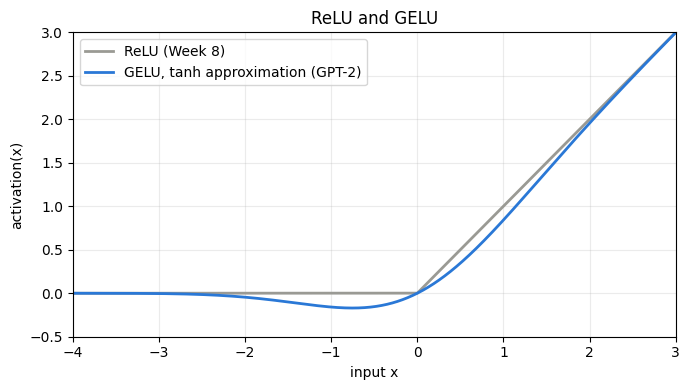

In [17]:
from transformers.activations import ACT2FN

z = torch.linspace(-6, 6, 10001)
gelu_hf = ACT2FN['gelu_new'](z) # the activation named in GPT-2's config
gelu_tanh = nn.GELU(approximate='tanh')(z)
gelu_exact = nn.GELU()(z)
print('max |nn.GELU(tanh) - gelu_new|:', (gelu_tanh - gelu_hf).abs().max().item())
print('max |exact GELU    - gelu_new|:', (gelu_exact - gelu_hf).abs().max().item())
assert torch.allclose(gelu_tanh, gelu_hf, atol=1e-6)
assert MLP(toy_config)(x).shape == x.shape
print('GELU and MLP shape checks passed.')

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(z, torch.relu(z), color='#9a9a94', linewidth=2, label='ReLU (Week 8)')
ax.plot(z, gelu_tanh, color='#2a78d6', linewidth=2, label='GELU, tanh approximation (GPT-2)')
ax.set_xlim(-4, 3)
ax.set_ylim(-0.5, 3)
ax.set_title('ReLU and GELU')
ax.set_xlabel('input x')
ax.set_ylabel('activation(x)')
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

### The Transformer Block

The block is my Week 8 `Block` with GPT-2 names and the new attention and MLP modules:

\[
x' = x + \operatorname{Attention}(\operatorname{LN}_1(x)),\qquad
x'' = x' + \operatorname{MLP}(\operatorname{LN}_2(x')).
\]

Attention is the step where tokens **communicate**; the MLP is the step where each token **computes** on what it gathered. The residual stream `x` passes through the block unchanged except for the two additions, so gradients have a direct path from the loss to every layer. GPT-2 moved LayerNorm from after each sublayer (the original Transformer) to before it, and added the final `ln_f`; my Week 8 model already followed this pre-normalized layout.

In [18]:
class Block(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x)) # communication
        x = x + self.mlp(self.ln_2(x)) # computation
        return x

### The Full Model and Weight Tying

`GPT` follows my Week 8 language model: token embeddings plus position embeddings, the stack of blocks, the final LayerNorm, and the vocabulary projection. The modules sit in an `nn.ModuleDict` called `transformer`, so the parameter names become `transformer.wte.weight`, `transformer.h.0.attn.c_attn.weight`, and so on, exactly the Hugging Face names.

Two details differ from Week 8. The forward pass keeps the logits as `(B,T,vocab_size)` and only flattens them inside the loss, and it refuses sequences longer than `block_size`, because the position table has only 1,024 rows.

**Weight tying.** `wte` maps a token ID to a 768-dimensional vector: its weight is `(50257, 768)`. `lm_head` maps a 768-dimensional vector to 50,257 scores: as an `nn.Linear(768, 50257)`, its weight is also `(50257, 768)`, and the score of token \(i\) is the dot product of the final hidden state with row \(i\). Both matrices therefore hold **one vector per token**, and GPT-2 uses the same vector for both purposes: tokens with similar embeddings receive similar output scores. The assignment `self.transformer.wte.weight = self.lm_head.weight` makes both modules point at one `nn.Parameter`. It saves \(50257\times768=38{,}597{,}376\) parameters, about 31% of an untied model, and the gradient of that matrix receives contributions from both uses.

In [19]:
class GPT(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.config = config

        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

        # weight sharing scheme: one (vocab_size, n_embd) matrix for the input and the output
        self.transformer.wte.weight = self.lm_head.weight

    def forward(self, idx, targets=None):
        # idx is of shape (B, T)
        B, T = idx.size()
        assert T <= self.config.block_size, f"Cannot forward sequence of length {T}, block size is only {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device) # shape (T)
        pos_emb = self.transformer.wpe(pos) # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx) # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layernorm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x) # (B, T, vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

#### Checks on a Small Configuration

Before loading 124M parameters, I repeat my Week 8 pre-training checks on a two-layer model: output shape, finite logits and loss, a gradient for every parameter, causal isolation, and the context-length limit.

In [20]:
torch.manual_seed(seed)
toy_model = GPT(toy_config)
idx = torch.randint(toy_config.vocab_size, (2, 8))
targets = torch.randint(toy_config.vocab_size, (2, 8))
logits, loss = toy_model(idx, targets)
print('idx', tuple(idx.shape), '-> logits', tuple(logits.shape), '| loss', round(loss.item(), 4))
assert logits.shape == (2, 8, toy_config.vocab_size)
assert torch.isfinite(logits).all() and torch.isfinite(loss)

loss.backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all() and p.grad.abs().sum() > 0 for p in toy_model.parameters())
toy_model.zero_grad(set_to_none=True)

changed = idx.clone()
changed[:, 4:] = (changed[:, 4:] + 1) % toy_config.vocab_size
with torch.no_grad():
    assert torch.allclose(toy_model(idx)[0][:, :4], toy_model(changed)[0][:, :4], atol=1e-6)

too_long = torch.zeros((1, toy_config.block_size + 1), dtype=torch.long)
try:
    toy_model(too_long)
    context_checked = False
except AssertionError as e:
    context_checked = True
    print('AssertionError:', e)
assert context_checked
print('Shape, finite-value, gradient, causal-mask, and context-length checks passed.')

idx (2, 8) -> logits (2, 8, 100) | loss 4.7322
AssertionError: Cannot forward sequence of length 17, block size is only 16
Shape, finite-value, gradient, causal-mask, and context-length checks passed.


#### Weight Tying in the Full-Size Model

Now the full GPT-2 configuration. If tying works, the two names refer to one parameter object with one storage, `parameters()` yields it once, and the unique count must be exactly the 124,439,808 measured for the Hugging Face model.

In [21]:
model = GPT(GPTConfig())
n_mine = sum(p.numel() for p in model.parameters())
n_mine_state_dict = sum(v.numel() for v in model.state_dict().values())
print(f'unique parameters:            {n_mine:>12,}')
print(f'sum over state-dict entries:  {n_mine_state_dict:>12,}')
print(f'an untied model would have:   {n_mine + model.lm_head.weight.numel():>12,}')
assert model.lm_head.weight is model.transformer.wte.weight
assert model.lm_head.weight.data_ptr() == model.transformer.wte.weight.data_ptr()
assert n_mine == n_unique == 124_439_808
assert sorted(model.state_dict().keys()) == sorted(sd_hf.keys()) # same names, mask buffer excluded
print('Weight-tying, parameter-count, and state-dict-name checks passed.')

unique parameters:             124,439,808
sum over state-dict entries:   163,037,184
an untied model would have:    163,037,184
Weight-tying, parameter-count, and state-dict-name checks passed.


### Loading the Hugging Face Weights: Why Some Must Be Transposed

OpenAI's original GPT-2 code was written in TensorFlow, and its projections were implemented as 1-D convolutions with kernel size 1. Hugging Face kept this as a `Conv1D` module that stores its weight as **`(in_features, out_features)`** and computes

\[
y = xW + b.
\]

PyTorch's `nn.Linear` stores **`(out_features, in_features)`** and computes

\[
y = xW^{\top} + b.
\]

Both layers compute the same function if my `nn.Linear` weight is the transpose of the `Conv1D` weight. This applies to the four projection matrices of every block, \(4\times12=48\) tensors:

- `attn.c_attn.weight`: `(768, 2304)` → `(2304, 768)`
- `attn.c_proj.weight`: `(768, 768)` → `(768, 768)`
- `mlp.c_fc.weight`: `(768, 3072)` → `(3072, 768)`
- `mlp.c_proj.weight`: `(3072, 768)` → `(768, 3072)`

`attn.c_proj.weight` is square, so a forgotten transpose would **not** raise a shape error; it would silently load the wrong matrix. This is why the loader below decides by name rather than by shape. Biases, LayerNorm parameters, and the embedding tables (`wte`, `wpe`) are not affected: biases and LayerNorm parameters are vectors, and embedding tables are lookups whose rows are already one vector per token or position. `lm_head.weight` is the tied `wte.weight`, already `(50257, 768)` in both conventions.

The next cell checks the convention directly on the first block's `c_fc`.

In [22]:
c_fc_hf = model_hf.transformer.h[0].mlp.c_fc
print(type(c_fc_hf).__name__, 'weight', tuple(c_fc_hf.weight.shape), '| my nn.Linear weight', tuple(model.transformer.h[0].mlp.c_fc.weight.shape))
with torch.no_grad():
    x_check = torch.randn(3, 768)
    y_conv = c_fc_hf(x_check)
    y_formula = x_check @ c_fc_hf.weight + c_fc_hf.bias # y = xW + b with W of shape (in, out)
    y_linear = F.linear(x_check, c_fc_hf.weight.t(), c_fc_hf.bias) # nn.Linear with the transposed weight
print('max |Conv1D - (xW + b)|:', (y_conv - y_formula).abs().max().item())
print('max |Conv1D - Linear(W.T)|:', (y_conv - y_linear).abs().max().item())
assert torch.allclose(y_conv, y_formula, atol=1e-5) and torch.allclose(y_conv, y_linear, atol=1e-5)
print('Conv1D convention check passed.')

Conv1D weight (768, 3072) | my nn.Linear weight (3072, 768)
max |Conv1D - (xW + b)|: 1.9073486328125e-06
max |Conv1D - Linear(W.T)|: 0.0
Conv1D convention check passed.


`from_pretrained` builds my model with the GPT-2 configuration, reads the Hugging Face state dict, and copies every tensor by name. The two key sets must be identical: no tensor may be missing, unexpected, or skipped. Shapes are checked before each copy, transposed shapes for the four Conv1D weights. The function is attached to the `GPT` class defined above, so it can be called as `GPT.from_pretrained('gpt2')`.

In [23]:
def from_pretrained(cls, model_type):
    # Loads pretrained GPT-2 model weights from huggingface
    assert model_type == 'gpt2' # GPT-2 small (124M) is the model used this week
    config = GPTConfig(n_layer=12, n_head=12, n_embd=768, vocab_size=50257, block_size=1024)
    model = cls(config)
    sd = model.state_dict() # tensors share storage with the model's parameters
    sd_keys = set(sd.keys())

    model_hf = GPT2LMHeadModel.from_pretrained('openai-community/gpt2')
    sd_hf = model_hf.state_dict()
    sd_keys_hf = set(sd_hf.keys())
    assert sd_keys == sd_keys_hf, f"missing: {sorted(sd_keys_hf - sd_keys)}, unexpected: {sorted(sd_keys - sd_keys_hf)}"

    # the openai checkpoints use a "Conv1D" module, but I only want to use a vanilla Linear
    # this means that I have to transpose these weights when I import them
    transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
    n_transposed, n_copied = 0, 0
    for k in sorted(sd_keys_hf):
        if any(k.endswith(w) for w in transposed):
            # special treatment for the Conv1D weights we need to transpose
            assert sd_hf[k].shape[::-1] == sd[k].shape, k
            with torch.no_grad():
                sd[k].copy_(sd_hf[k].t())
            n_transposed += 1
        else:
            # vanilla copy over the other parameters
            assert sd_hf[k].shape == sd[k].shape, k
            with torch.no_grad():
                sd[k].copy_(sd_hf[k])
            n_copied += 1
    print(f'loaded {n_transposed + n_copied} state-dict entries: {n_transposed} transposed, {n_copied} copied directly')
    return model

GPT.from_pretrained = classmethod(from_pretrained)

In [24]:
model = GPT.from_pretrained('gpt2')
model.to(device)
model.eval()
model_hf.to(device)
print('my model on', next(model.parameters()).device, '| reference on', next(model_hf.parameters()).device)

loaded 149 state-dict entries: 48 transposed, 101 copied directly


my model on cuda:0 | reference on cuda:0


A successful copy is not yet proof that the values are in the right place. The next cell compares every tensor of my model with the corresponding Hugging Face tensor (transposed where required) for **exact** equality, and checks that loading did not break the weight tying.

In [25]:
transposed = ['attn.c_attn.weight', 'attn.c_proj.weight', 'mlp.c_fc.weight', 'mlp.c_proj.weight']
sd_mine = model.state_dict()
sd_hf = model_hf.state_dict()
n_equal = 0
for k, v in sd_hf.items():
    expected = v.t() if any(k.endswith(w) for w in transposed) else v
    assert torch.equal(sd_mine[k], expected), k
    n_equal += 1
assert n_equal == len(sd_mine) == len(sd_hf) == 149
assert model.lm_head.weight.data_ptr() == model.transformer.wte.weight.data_ptr()
print(f'{n_equal} of {len(sd_hf)} tensors are exactly equal to the Hugging Face tensors; weight tying is intact.')

149 of 149 tensors are exactly equal to the Hugging Face tensors; weight tying is intact.


### Numerical Equivalence of the Logits

The real test is the forward pass. Both models receive the **same token IDs**: four windows of 64 GPT-2 tokens from the beginning of Tiny Shakespeare (my Week 8 corpus). Targets are the same windows shifted by one token, as in Week 8. Both models are in evaluation mode, in float32, without TF32. I compare:

- the logit shapes;
- the maximum and mean absolute logit difference, with `torch.allclose(atol=1e-4, rtol=1e-5)`;
- the predicted next token (argmax) at every position;
- the cross-entropy loss on identical targets. Hugging Face's `labels=` argument shifts targets internally, so I compute its loss from its logits with the same `F.cross_entropy` call instead.

The tolerances were fixed before running the comparison.

In [26]:
enc = tiktoken.get_encoding('gpt2')
with open(data_dir / 'input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

B, T = 4, 64
buf = torch.tensor(enc.encode(text[:2000])[:B*T + 1], dtype=torch.long)
x_verify = buf[:-1].view(B, T).to(device) # inputs
y_verify = buf[1:].view(B, T).to(device) # targets: the next token at every position
print('x', tuple(x_verify.shape), '| y', tuple(y_verify.shape))
print(repr(enc.decode(x_verify[0, :16].tolist())))

with torch.no_grad():
    logits_mine, loss_mine = model(x_verify, y_verify)
    logits_hf = model_hf(x_verify).logits
    loss_hf = F.cross_entropy(logits_hf.view(-1, logits_hf.size(-1)), y_verify.view(-1))

diff = (logits_mine - logits_hf).abs()
same_argmax = (logits_mine.argmax(-1) == logits_hf.argmax(-1)).sum().item()
print('logits shape    mine', tuple(logits_mine.shape), '| HF', tuple(logits_hf.shape))
print(f'logit range     [{logits_hf.min().item():.2f}, {logits_hf.max().item():.2f}]')
print(f'max |diff|      {diff.max().item():.3e}')
print(f'mean |diff|     {diff.mean().item():.3e}')
print(f'same argmax     {same_argmax} / {B*T} positions')
print(f'loss            mine {loss_mine.item():.6f} | HF {loss_hf.item():.6f} | |diff| {abs(loss_mine.item() - loss_hf.item()):.2e}')

# allclose checks |a - b| <= atol + rtol * |b| elementwise; how much of that allowance is used?
allowed = 1e-4 + 1e-5 * logits_hf.abs()
worst = (diff / allowed).argmax()
print(f'largest |diff| / (atol + rtol*|logit|): {(diff / allowed).max().item():.3f}'
      f' (|diff| {diff.flatten()[worst].item():.2e} at a logit of {logits_hf.flatten()[worst].item():.2f})')
print(f'entries with |diff| > atol alone: {(diff > 1e-4).sum().item():,} of {diff.numel():,}')
print(f'max relative difference |diff| / |logit|: {(diff / logits_hf.abs()).max().item():.2e}')

x (4, 64) | y (4, 64)
'First Citizen:\nBefore we proceed any further, hear me speak.\n\n'


logits shape    mine (4, 64, 50257) | HF (4, 64, 50257)
logit range     [-342.36, 158.19]
max |diff|      7.782e-04
mean |diff|     3.046e-05
same argmax     256 / 256 positions
loss            mine 4.961894 | HF 4.961895 | |diff| 1.43e-06
largest |diff| / (atol + rtol*|logit|): 0.734 (|diff| 1.52e-04 at a logit of -10.65)
entries with |diff| > atol alone: 440,275 of 12,865,792
max relative difference |diff| / |logit|: 1.55e-02


In [27]:
assert logits_mine.shape == logits_hf.shape == (B, T, 50257)
assert torch.allclose(logits_mine, logits_hf, atol=1e-4, rtol=1e-5)
assert torch.equal(logits_mine.argmax(-1), logits_hf.argmax(-1))
assert abs(loss_mine.item() - loss_hf.item()) < 1e-5
print('Logit verification passed: my GPT-2 reproduces the Hugging Face logits within atol=1e-4, rtol=1e-5.')

Logit verification passed: my GPT-2 reproduces the Hugging Face logits within atol=1e-4, rtol=1e-5.


#### Where Do the Remaining Differences Come From?

A passing `allclose` could still hide an error that happens to be small for this input. Comparing the residual stream after every block shows how the difference grows through the network. With `output_hidden_states=True`, Hugging Face returns 13 tensors: the embedding sum, the outputs of blocks 1 to 11, and the output of block 12 **after** `ln_f`. I compute the same 13 tensors with my modules.

In [28]:
with torch.no_grad():
    hidden_hf = model_hf(x_verify, output_hidden_states=True).hidden_states
    pos = torch.arange(T, device=device)
    h = model.transformer.wte(x_verify) + model.transformer.wpe(pos)
    hidden_mine = [h]
    for block in model.transformer.h:
        h = block(h)
        hidden_mine.append(h)
    hidden_mine[-1] = model.transformer.ln_f(hidden_mine[-1]) # HF stores the last state after ln_f

assert len(hidden_hf) == len(hidden_mine) == 13
labels = ['embeddings'] + [f'block {i}' for i in range(1, 12)] + ['block 12 + ln_f']
lines = ['| Residual stream after | Max abs value | Max abs difference | Mean abs difference |', '|---|---:|---:|---:|']
for label, a, b in zip(labels, hidden_mine, hidden_hf):
    d = (a - b).abs()
    lines.append(f'| {label} | {b.abs().max().item():.2f} | {d.max().item():.2e} | {d.mean().item():.2e} |')
display(Markdown('\n'.join(lines)))
assert torch.equal(hidden_mine[0], hidden_hf[0]) # identical embeddings: same lookup, same addition

| Residual stream after | Max abs value | Max abs difference | Mean abs difference |
|---|---:|---:|---:|
| embeddings | 4.64 | 0.00e+00 | 0.00e+00 |
| block 1 | 109.57 | 3.81e-05 | 4.09e-07 |
| block 2 | 626.77 | 1.83e-04 | 5.40e-07 |
| block 3 | 2496.88 | 2.20e-03 | 7.98e-07 |
| block 4 | 2686.33 | 1.71e-03 | 1.09e-06 |
| block 5 | 2839.00 | 1.46e-03 | 1.27e-06 |
| block 6 | 2940.62 | 1.22e-03 | 1.53e-06 |
| block 7 | 3001.69 | 1.22e-03 | 1.82e-06 |
| block 8 | 3038.86 | 1.22e-03 | 2.18e-06 |
| block 9 | 3062.12 | 9.77e-04 | 2.62e-06 |
| block 10 | 3074.55 | 9.77e-04 | 3.19e-06 |
| block 11 | 3078.23 | 9.77e-04 | 4.01e-06 |
| block 12 + ln_f | 278.22 | 6.10e-04 | 5.69e-07 |

### What the Comparison Shows

**Loading.** All 149 state-dict entries were loaded by name: 48 transposed Conv1D weights and 101 direct copies. After loading, every tensor of my model is **exactly equal** to the corresponding Hugging Face tensor, and `wte` and `lm_head` still share storage.

**Logits.** On the same `(4, 64)` input, the maximum absolute logit difference is **7.782e-04** and the mean is **3.046e-05**. Both models choose the same next token at all 256 positions, and the losses are 4.961894 and 4.961895. The `allclose(atol=1e-4, rtol=1e-5)` assertion passes. Its criterion is \(|a-b|\le \text{atol}+\text{rtol}\,|b|\) for every element, and the logits range from −342 to 158, so the relative term matters. The absolute tolerance alone is exceeded by 440,275 of the 12.9 million logits (3.4%), including the largest difference. The tightest element uses 73% of its allowance: a difference of 1.52e-04 at a logit of −10.65. The largest relative difference, 1.55e-02, comes from logits very close to zero, where any rounding error is large relative to the value.

**Where the differences come from.** The embedding sums are identical. After block 1, the largest difference is 3.81e-05 at values up to 110. From block 3 on, the largest values in the residual stream reach about 2,500 to 3,080, and the largest absolute differences are about 1e-03. Relative to values of 3,000, that is \(3\times10^{-7}\), the size of float32 rounding (machine epsilon \(1.2\times10^{-7}\)). The mean differences grow smoothly from 4.1e-07 to 4.0e-06 over the 12 blocks, with no jump at any layer, and `ln_f` divides the large values back down. A real mistake would look different. A missing transpose, the exact instead of the tanh GELU, or a wrong attention scale would change the result at the first block where it occurs, by much more than rounding. The exact GELU alone differs from `gelu_new` by up to 4.7e-04 per activation.

**Conclusion.** My GPT-2 implementation, with the Hugging Face weights loaded, computes the same function as the reference model up to float32 rounding. The assertions on shapes, logits, argmax tokens, and loss all pass.

# 3. Modeli konuştur. Sampling döngüsünü yaz, top-k ile örnek üret. Önce İngilizce bir başlangıç cümlesi dene, sonra Türkçe bir cümle. GPT-2'nin Türkçe çıktısı neden kötü? Aynı Türkçe cümle GPT-2'nin tokenizer'ında kaç token tutuyor? Geçen haftaki sonuçlarınla bağla. (0:31:00 - 0:45:50)

## 3. Sampling from GPT-2

Generation repeats the Week 8 loop, now with BPE tokens:

1. **Encode** the prompt with the GPT-2 tokenizer into a `(B,T)` tensor of IDs.
2. **Run** the model on the last `block_size` tokens at most.
3. **Select** the logits of the final position, `(B,vocab_size)`: they score the next token.
4. **Divide by the temperature** \(\tau\). \(\tau<1\) sharpens the distribution; \(\tau>1\) flattens it.
5. **Keep the top-k** logits and discard the others.
6. **Softmax** the kept logits into probabilities that sum to one.
7. **Sample** one token with `torch.multinomial`.
8. **Append** it to the sequence and repeat.

With \(\mathcal{K}_k\) the \(k\) tokens with the highest logits,

\[
p(i)=\frac{\exp(z_i/\tau)}{\sum_{j\in\mathcal{K}_k}\exp(z_j/\tau)}\quad\text{for } i\in\mathcal{K}_k,\qquad p(i)=0\ \text{otherwise}.
\]

**Why top-k?** The vocabulary has 50,257 tokens. Most of them are individually unlikely, but together they hold a noticeable share of the probability. Plain sampling regularly picks one of them, and one bad token can derail the rest of the text, because the model conditions on its own output. Top-k removes this long tail. **Greedy decoding** always takes the argmax: it is deterministic and tends to repeat itself. Top-k sampling keeps randomness among plausible candidates; `top_k=1` reduces to greedy decoding. \(k=50\) is the Hugging Face default, which the lecture uses.

My loop recomputes the whole context at every step; there is no key/value cache. For a few dozen new tokens this is fast enough. Evaluation mode and `torch.no_grad()` disable dropout and graph construction, as in Week 8. A separate `torch.Generator` makes sampling reproducible without touching the global random state.

In [29]:
def sample_next(logits, temperature=1.0, top_k=None, generator=None):
    # logits: (B, vocab_size) scores for the next token -> (B, 1) sampled token IDs
    logits = logits / temperature
    if top_k is not None:
        topk_logits, topk_ids = torch.topk(logits, top_k, dim=-1) # (B, k), sorted
        probs = F.softmax(topk_logits, dim=-1) # renormalize over the k candidates only
        ix = torch.multinomial(probs, num_samples=1, generator=generator) # (B, 1) index into the top-k
        return torch.gather(topk_ids, -1, ix) # (B, 1) token IDs
    probs = F.softmax(logits, dim=-1)
    return torch.multinomial(probs, num_samples=1, generator=generator)

@torch.no_grad()
def generate(model, idx, max_new_tokens, temperature=1.0, top_k=50, generator=None):
    # idx is (B, T) array of indices in the current context
    was_training = model.training
    model.eval()
    for _ in range(max_new_tokens):
        # crop idx to the last block_size tokens
        idx_cond = idx[:, -model.config.block_size:]
        logits, _ = model(idx_cond)
        # focus only on the last time step
        logits = logits[:, -1, :] # (B, vocab_size)
        idx_next = sample_next(logits, temperature, top_k, generator) # (B, 1)
        # append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
    model.train(was_training)
    return idx

def make_generator(s):
    return torch.Generator(device=device).manual_seed(s)

### Checks Before Generating Text

- **Length and valid IDs:** the output keeps the prompt and adds exactly `max_new_tokens` IDs in `[0, 50257)`.
- **Reproducibility:** the same generator seed gives the same tokens; a different seed gives different tokens.
- **Top-k restriction:** 2,000 draws from one next-token distribution must all lie in its 50 highest-scoring tokens.
- **Greedy decoding:** `top_k=1` must equal an explicit argmax loop.
- **Agreement with Hugging Face:** my greedy continuation must equal `model_hf.generate(do_sample=False)` token for token. This extends the logit check to the full autoregressive loop. Hugging Face uses a key/value cache, so it reaches the same tokens through a different sequence of computations.
- **Context cropping:** a prompt longer than 1,024 tokens must still work, because only the last 1,024 tokens are fed to the model.

In [30]:
prompt = "Hello, I'm a language model,"
prompt_ids = torch.tensor([enc.encode(prompt)], dtype=torch.long, device=device) # (1, P)
P = prompt_ids.size(1)
print('prompt tokens:', prompt_ids[0].tolist())

out = generate(model, prompt_ids.repeat(3, 1), max_new_tokens=20, top_k=50, generator=make_generator(42))
assert out.shape == (3, P + 20)
assert torch.equal(out[:, :P], prompt_ids.repeat(3, 1))
assert out.min().item() >= 0 and out.max().item() < 50257
assert torch.equal(out, generate(model, prompt_ids.repeat(3, 1), 20, top_k=50, generator=make_generator(42)))
assert not torch.equal(out, generate(model, prompt_ids.repeat(3, 1), 20, top_k=50, generator=make_generator(43)))

with torch.no_grad():
    last_logits = model(prompt_ids)[0][:, -1, :] # (1, vocab_size)
allowed = set(torch.topk(last_logits, 50, dim=-1).indices[0].tolist())
draws = sample_next(last_logits.expand(2000, -1), top_k=50, generator=make_generator(0)) # 2,000 independent draws
drawn = set(draws.flatten().tolist())
print(f'2,000 top-k draws used {len(drawn)} distinct tokens, all inside the top 50: {drawn <= allowed}')
assert drawn <= allowed

greedy = prompt_ids
with torch.no_grad():
    for _ in range(30):
        greedy = torch.cat((greedy, model(greedy)[0][:, -1, :].argmax(-1, keepdim=True)), dim=1)
assert torch.equal(generate(model, prompt_ids, 30, top_k=1), greedy)

greedy_hf = model_hf.generate(prompt_ids, attention_mask=torch.ones_like(prompt_ids), max_new_tokens=30,
                              do_sample=False, pad_token_id=enc.eot_token)
print('greedy (mine):', repr(enc.decode(greedy[0].tolist())))
print('greedy (HF):  ', repr(enc.decode(greedy_hf[0].tolist())))
assert torch.equal(greedy_hf, greedy)

long_prompt = torch.tensor([enc.encode(text[:6000])], dtype=torch.long, device=device)
assert long_prompt.size(1) > model.config.block_size
assert generate(model, long_prompt, 2, top_k=50, generator=make_generator(1)).size(1) == long_prompt.size(1) + 2
print('long prompt:', long_prompt.size(1), 'tokens, cropped to the last', model.config.block_size)
print('Length, valid-ID, reproducibility, top-k, greedy, Hugging Face greedy, and cropping checks passed.')

prompt tokens: [15496, 11, 314, 1101, 257, 3303, 2746, 11]


2,000 top-k draws used 50 distinct tokens, all inside the top 50: True


greedy (mine): "Hello, I'm a language model, not a programming language. I'm a language model. I'm a language model. I'm a language model. I'm a language model. I"
greedy (HF):   "Hello, I'm a language model, not a programming language. I'm a language model. I'm a language model. I'm a language model. I'm a language model. I"
long prompt: 1690 tokens, cropped to the last 1024
Length, valid-ID, reproducibility, top-k, greedy, Hugging Face greedy, and cropping checks passed.


### English Prompts

I sample four continuations of 40 tokens for two English prompts: the lecture's prompt, and a plain sentence about Istanbul whose Turkish translation I use in the next section. Settings: `top_k=50`, `temperature=1.0`, fixed generator seeds.

In [31]:
def show_samples(prompt, num_return_sequences=4, max_new_tokens=40, top_k=50, temperature=1.0, sample_seed=seed):
    ids = torch.tensor([enc.encode(prompt)], dtype=torch.long, device=device).repeat(num_return_sequences, 1)
    out = generate(model, ids, max_new_tokens, temperature=temperature, top_k=top_k, generator=make_generator(sample_seed))
    print(f'prompt: {prompt!r} ({ids.size(1)} tokens) | top_k={top_k}, temperature={temperature}, seed={sample_seed}')
    texts = []
    for row in out:
        texts.append(enc.decode(row.tolist()))
        print('>', texts[-1].replace('\n', ' \\n '))
    print()
    return texts

english_prompt = "Today the weather in Istanbul is very nice, so"
samples = {}
samples['lecture'] = show_samples("Hello, I'm a language model,")
samples['english'] = show_samples(english_prompt)

prompt: "Hello, I'm a language model," (8 tokens) | top_k=50, temperature=1.0, seed=1337
> Hello, I'm a language model, not a model of how I feel. Sometimes I get a little antsy," he added. \n  \n Sachin said, "I think one of the ways we'll move forward is through technology
> Hello, I'm a language model, as is my wife. I started studying Python on a whim to learn it so I could write and create libraries. I eventually decided to write a language model. I have spent nearly a decade doing this
> Hello, I'm a language model, and this article provides some practical examples of how you can design your own applications where you only have to modify the syntax and syntax of those application components, with your expressiveness and speed. \n  \n With
> Hello, I'm a language model, and I wanted to create something that was more conversational, more interactive. \n  \n Tired of typing about an issue or two?" \n  \n We love to build experiences with words, so I decided



prompt: 'Today the weather in Istanbul is very nice, so' (10 tokens) | top_k=50, temperature=1.0, seed=1337
> Today the weather in Istanbul is very nice, so I'm really curious if the water source is from the river Ogin." \n  \n It's good news that there's no more water in Istanbul - the city currently receives 6.3 million barrels a
> Today the weather in Istanbul is very nice, so much so that we started to be able to find the people here. I thought that it would go over well, but then I saw that the people are all different," said Gülen, who
> Today the weather in Istanbul is very nice, so we are not sure how I am going to stay in and watch such beautiful beaches. As the weather gets colder the beach becomes more dark and it's like I go to sleep right after sunset. The
> Today the weather in Istanbul is very nice, so we started taking the buses and there was a lot going on. It was good," Aydin, 39, says. "Even when we have breakfast, we don't have enough." \n  \n 



### Reading the English Samples

The greedy continuation from the lecture prompt is identical in both implementations, and it falls into a loop: *I'm a language model.* repeats four times. This repetition is typical of greedy decoding.

The top-k samples are different. Each one is grammatical English with ordinary punctuation, quotation marks, and paragraph breaks, in the style of web articles and forum posts. Within a sentence or two, the text is fluent. Over 40 tokens, it drifts. The lecture prompt continues with a quote attributed to "Sachin", a first-person story about learning Python, and an article about designing applications. The Istanbul prompt continues with invented details: a "river Ogin", "6.3 million barrels" of water, and speakers named Gülen and Aydin. The model has learned which words and constructions follow each other in English web text. It does not keep to the prompt's topic, and nothing checks its facts. Eight samples from two prompts show this behavior but do not measure the model's quality.

### Turkish Prompts

The first Turkish prompt is the translation of the English Istanbul sentence; the second asks for a continuation about Turkey's most populated city. Both contain Turkish-specific letters (`İ`, `ç`, `ü`, `ı`, `ş`). The settings are the same as for English. `enc.decode` replaces invalid UTF-8 with `�`, as my Week 9 `decode` did, so a continuation that stops in the middle of a two-byte Turkish letter stays printable.

In [32]:
turkish_prompt = "Bugün İstanbul'da hava çok güzel, bu yüzden"
samples['turkish'] = show_samples(turkish_prompt)
samples['turkish_2'] = show_samples("Türkiye'nin en kalabalık şehri")

prompt: "Bugün İstanbul'da hava çok güzel, bu yüzden" (22 tokens) | top_k=50, temperature=1.0, seed=1337
> Bugün İstanbul'da hava çok güzel, bu yüzden, ðu sekıktörün, \n  \n yüztazmı gördı, \n  \n yüztadün müzgen g
> Bugün İstanbul'da hava çok güzel, bu yüzden! \n  \n (You can do this online on Google Docs, Google Groups, or Bing): \n  \n https://www.google.com/maps/js/?alt=%3A%
> Bugün İstanbul'da hava çok güzel, bu yüzden göt zekre çov. Řeylle ve zammeşığan çok kellerığlu zukan, rözne r
> Bugün İstanbul'da hava çok güzel, bu yüzden çok hükur. \n  \n "O yu hava! Where are you? There's only one thing he wants to speak a word about. \n  \n "Ah! Ah



prompt: "Türkiye'nin en kalabalık şehri" (16 tokens) | top_k=50, temperature=1.0, seed=1337
> Türkiye'nin en kalabalık şehri yık şehri yaqıtııcızımı (Tashkanen) Yükülen yüşkülen yükü
> Türkiye'nin en kalabalık şehrii şekşırnıi iğuriyıl şekciuü makırıık lışnüşin ışilı
> Türkiye'nin en kalabalık şehriyüş, Hengfült, Tönölen, Dütürküyün, Kizvazüt, Fülktün, W
> Türkiye'nin en kalabalık şehri, iğaştılı zamnışli ñem, nakab, yaman, vikramm olam, lçte İkta



In [33]:
def pieces(ids_, encoding=enc):
    return [encoding.decode_single_token_bytes(t).decode('utf-8', errors='backslashreplace') for t in ids_]

for label, s in [('English', english_prompt), ('Turkish', turkish_prompt)]:
    ids_ = enc.encode(s)
    print(f'{label}: {len(s)} characters, {len(s.split())} words, {len(ids_)} GPT-2 tokens')
    print('   ', pieces(ids_))

turkish_sample_ids = enc.encode(''.join(samples['turkish']))
print('\nreplacement characters in the decoded Turkish samples:', ''.join(samples['turkish']).count('�'))

English: 46 characters, 9 words, 10 GPT-2 tokens
    ['Today', ' the', ' weather', ' in', ' Istanbul', ' is', ' very', ' nice', ',', ' so']
Turkish: 43 characters, 7 words, 22 GPT-2 tokens
    ['Bug', 'ü', 'n', ' \\xc4', '\\xb0', 'stanbul', "'d", 'a', ' ha', 'va', ' \\xc3', '\\xa7', 'ok', ' g', 'ü', 'zel', ',', ' bu', ' y', 'ü', 'z', 'den']

replacement characters in the decoded Turkish samples: 0


### Why Is GPT-2's Turkish So Poor?

**The samples.** None of the eight Turkish continuations contains a grammatical Turkish sentence:

- Several produce strings with Turkish letters but almost no Turkish words: *yüztazmı gördı*, *göt zekre çov*, *kellerığlu zukan*. A few real words appear (*çok*, *ve*, *hava*), mostly repeated from the prompt.
- Characters from other alphabets appear: `ð`, `Ř`, `ñ`.
- Two samples switch to English (a Google Docs and Maps passage with a URL; *"Where are you?"*).
- The second prompt produces lists of invented, Turkish-looking names (*Hengfült, Tönölen, Dütürküyün*).

**Token fragmentation.** The 7-word Turkish prompt needs **22 GPT-2 tokens**; its 9-word English translation needs **10**. Every English word is a single token, mostly with its leading space. In Turkish:

- `İ` and `ç` are split into their two UTF-8 bytes (`' \xc4'` + `'\xb0'`, `' \xc3'` + `'\xa7'`), so the model has to produce them byte by byte.
- `ü` stands alone between fragments (`Bug` `ü` `n`, ` y` `ü` `z` `den`).
- Even common words are split (` ha` + `va`).

Each extra token is one more prediction that can go wrong, and a word spelled over many fragments leaves more room for invented spellings. The decoded samples contain no `�`: every sampled byte sequence happened to form valid UTF-8.

**Tokenization is not the main reason.** The GPT-2 tokenizer can represent Turkish without unknown tokens, and it has learned many Latin-letter fragments that occur in Turkish (`stanbul`, `zel`, `den`). The deeper cause is the **training data**. The GPT-2 paper (Radford et al., 2019) states that non-English webpages were deliberately removed from WebText, the corpus on which GPT-2 was trained. GPT-2 therefore saw very little Turkish, and it has learned almost no Turkish vocabulary, morphology, or syntax. Token efficiency describes how text is cut into pieces; language ability is what the model learned about sequences of those pieces. Fragmentation makes Turkish more expensive and harder to spell, but a better tokenizer alone would not teach the model Turkish. Measuring GPT-2's loss on Turkish and English sentences (the optional bonus (b)) would quantify the difference; I have not run that experiment.

### GPT-2's Tokenizer on Turkish: Connecting with Week 9

In Week 9, I measured the Turkish paragraph from my corpus's held-out text and its English translation with GPT-4's `cl100k_base` and with my own 512-token tokenizers. GPT-2's `gpt2` encoding was not measured on Turkish there, so the GPT-2 rows below are **new measurements**. I use the same paragraph pair, the same held-out text, and the same counting conventions:

- **words:** `len(s.split())`; **bytes:** UTF-8 bytes; **tokens per word** = tokens / words; **bytes per token** = bytes / tokens.

The `cl100k_base` rows are recomputed here and must match the saved Week 9 table. The rows marked *saved Week 9* are copied from that notebook's output; I do not retrain the Week 9 tokenizers.

The three tokenizers differ in both **vocabulary size** and **training data**: `gpt2` has 50,257 tokens and belongs to a model trained on English-dominated WebText, `cl100k_base` about 100k tokens from undisclosed data, and my regex BPE 512 tokens learned only from my Turkish corpus. None of these comparisons isolates one factor.

First, a check that tiktoken's `gpt2` encoding is the tokenizer that belongs to the Hugging Face model.

In [34]:
tokenizer_hf = GPT2TokenizerFast.from_pretrained('openai-community/gpt2')
checks = [prompt, english_prompt, turkish_prompt, "Pijamalı hasta yağız şoföre çabucak güvendi. İzmir'de Işık 👋", text[:3000]]
for s in checks:
    assert tokenizer_hf.encode(s) == enc.encode(s)
assert len(tokenizer_hf) == enc.n_vocab == 50257
print('tiktoken gpt2 and the Hugging Face GPT-2 tokenizer give identical IDs on', len(checks), 'test strings.')

tiktoken gpt2 and the Hugging Face GPT-2 tokenizer give identical IDs on 5 test strings.


In [35]:
with open(data_dir / 'turkish_input.txt', 'r', encoding='utf-8') as f:
    turkish_text = f.read()
n = int(0.9*len(turkish_text)) # the Week 9 split: first 90% train, rest val
train_text, val_text = turkish_text[:n], turkish_text[n:]

turkish_paragraph = "Dün gece bir saniye bile uyuyamadım. Yatakta arkaüstü yatarak hep trendeki çocuğu düşündüm. Vagonun sarsıntılariyle kımıldıyan başını görür gibi oluyordum. Bol saçlı bir çocuk başı... Ne gözlerinin, ne saçlarının rengini, hattâ ne de ismini biliyordum. Ona hiç dikkat etmemiştim. Yanıbaşımda, bir adım ötemde durduğu halde bir kere merakla yüzüne bakmamıştım. Ayrılırken elini bile sıkmamıştım. Hiçbir şey, aman Yarabbi, kendi kızıma dair hiçbir şey bilmiyordum. Kadın muhakkak ki birçok şeyler sezmişti... Niçin bana o kadar hain bakmıştı? Herhalde bir şeyler tahmin etmişti... Ve kızı alıp gitti... Şimdi yoldalar... Tekerlekler bir raydan bir raya atlarken kızımın uyuyan başı hafifçe sarsılıyor..."

english_paragraph = "Last night I could not sleep for even a second. Lying on my back in bed, I kept thinking about the child on the train. I almost seemed to see her head stirring with the jolts of the carriage. A child's head with thick hair... I did not know the color of her eyes or of her hair, not even her name. I had paid no attention to her. Although she had stood right beside me, one step away, I had not once looked at her face with curiosity. When we parted, I had not even shaken her hand. Nothing, dear God, I knew nothing about my own daughter. The woman had surely sensed many things... Why had she looked at me so maliciously? She must have guessed something... And she took the girl and left... Now they are on their way... As the wheels jump from one rail to the next, my daughter's sleeping head is gently shaking..."

assert turkish_paragraph in val_text and turkish_paragraph not in train_text
enc_cl100k = tiktoken.get_encoding('cl100k_base')
for s in [turkish_paragraph, english_paragraph, val_text]:
    assert enc.decode(enc.encode(s)) == s and enc_cl100k.decode(enc_cl100k.encode(s)) == s
print('Turkish val_text:', len(val_text), 'characters | paragraph pair loaded and round-trip checks passed.')

Turkish val_text: 30281 characters | paragraph pair loaded and round-trip checks passed.


In [36]:
def describe(language, tokenizer, s, n_tokens):
    words = len(s.split())
    n_bytes = len(s.encode('utf-8'))
    return {'language': language, 'tokenizer': tokenizer, 'chars': len(s), 'bytes': n_bytes,
            'words': words, 'tokens': n_tokens, 'tokens_per_word': n_tokens / words,
            'bytes_per_token': n_bytes / n_tokens}

def show_rows(rows):
    lines = ['| Text | Tokenizer | Characters | Bytes | Words | Tokens | Tokens / word | Bytes / token |',
             '|---|---|---:|---:|---:|---:|---:|---:|']
    for r in rows:
        lines.append(f"| {r['language']} | {r['tokenizer']} | {r['chars']:,} | {r['bytes']:,} | {r['words']:,} | {r['tokens']:,} | {r['tokens_per_word']:.2f} | {r['bytes_per_token']:.2f} |")
    display(Markdown('\n'.join(lines)))

paragraph_rows = [
    describe('Turkish paragraph', 'gpt2 (GPT-2)', turkish_paragraph, len(enc.encode(turkish_paragraph))),
    describe('Turkish paragraph', 'cl100k_base (GPT-4)', turkish_paragraph, len(enc_cl100k.encode(turkish_paragraph))),
    describe('Turkish paragraph', 'regex BPE (512), saved Week 9', turkish_paragraph, 343),
    describe('English paragraph', 'gpt2 (GPT-2)', english_paragraph, len(enc.encode(english_paragraph))),
    describe('English paragraph', 'cl100k_base (GPT-4)', english_paragraph, len(enc_cl100k.encode(english_paragraph))),
    describe('English paragraph', 'regex BPE (512), saved Week 9', english_paragraph, 551),
]
assert paragraph_rows[1]['tokens'] == 296 and paragraph_rows[4]['tokens'] == 188 # the saved Week 9 cl100k_base counts
show_rows(paragraph_rows)

val_rows = [
    describe('Turkish val_text', 'gpt2 (GPT-2)', val_text, len(enc.encode(val_text))),
    describe('Turkish val_text', 'cl100k_base (GPT-4)', val_text, len(enc_cl100k.encode(val_text))),
    describe('Turkish val_text', 'basic BPE (512), saved Week 9', val_text, 15554),
    describe('Turkish val_text', 'regex BPE (512), saved Week 9', val_text, 15430),
]
assert val_rows[1]['tokens'] == 12463 # the saved Week 9 cl100k_base count
show_rows(val_rows)

| Text | Tokenizer | Characters | Bytes | Words | Tokens | Tokens / word | Bytes / token |
|---|---|---:|---:|---:|---:|---:|---:|
| Turkish paragraph | gpt2 (GPT-2) | 701 | 778 | 98 | 360 | 3.67 | 2.16 |
| Turkish paragraph | cl100k_base (GPT-4) | 701 | 778 | 98 | 296 | 3.02 | 2.63 |
| Turkish paragraph | regex BPE (512), saved Week 9 | 701 | 778 | 98 | 343 | 3.50 | 2.27 |
| English paragraph | gpt2 (GPT-2) | 816 | 816 | 159 | 188 | 1.18 | 4.34 |
| English paragraph | cl100k_base (GPT-4) | 816 | 816 | 159 | 188 | 1.18 | 4.34 |
| English paragraph | regex BPE (512), saved Week 9 | 816 | 816 | 159 | 551 | 3.47 | 1.48 |

| Text | Tokenizer | Characters | Bytes | Words | Tokens | Tokens / word | Bytes / token |
|---|---|---:|---:|---:|---:|---:|---:|
| Turkish val_text | gpt2 (GPT-2) | 30,281 | 33,468 | 4,020 | 15,478 | 3.85 | 2.16 |
| Turkish val_text | cl100k_base (GPT-4) | 30,281 | 33,468 | 4,020 | 12,463 | 3.10 | 2.69 |
| Turkish val_text | basic BPE (512), saved Week 9 | 30,281 | 33,468 | 4,020 | 15,554 | 3.87 | 2.15 |
| Turkish val_text | regex BPE (512), saved Week 9 | 30,281 | 33,468 | 4,020 | 15,430 | 3.84 | 2.17 |

In [37]:
gpt2_tr, cl_tr = paragraph_rows[0]['tokens'], paragraph_rows[1]['tokens']
gpt2_en, cl_en = paragraph_rows[3]['tokens'], paragraph_rows[4]['tokens']
print(f'Turkish / English token ratio: gpt2 {gpt2_tr / gpt2_en:.2f} | cl100k_base {cl_tr / cl_en:.2f}')
print(f'gpt2 / cl100k_base tokens:     Turkish {gpt2_tr / cl_tr:.2f} | English {gpt2_en / cl_en:.2f}')
for label, row in [('Turkish val_text', val_rows[0]), ('English paragraph', paragraph_rows[3])]:
    words_per_context = 1024 / row['tokens_per_word']
    print(f'1,024 gpt2 tokens hold about {words_per_context:.0f} words of {label} ({row["tokens_per_word"]:.2f} tokens per word)')

strip = lambda w: w.strip('.,?!;:«»')
print('\n--- longest Turkish words of the paragraph ---')
for w in sorted(set(map(strip, turkish_paragraph.split())), key=lambda w: (-len(w), w))[:6]: # ties: alphabetical
    print(f"{w:18} gpt2   {len(enc.encode(w)):2d}: {pieces(enc.encode(w))}")
    print(f"{'':18} cl100k {len(enc_cl100k.encode(w)):2d}: {pieces(enc_cl100k.encode(w), enc_cl100k)}")

Turkish / English token ratio: gpt2 1.91 | cl100k_base 1.57
gpt2 / cl100k_base tokens:     Turkish 1.22 | English 1.00
1,024 gpt2 tokens hold about 266 words of Turkish val_text (3.85 tokens per word)
1,024 gpt2 tokens hold about 866 words of English paragraph (1.18 tokens per word)

--- longest Turkish words of the paragraph ---
sarsıntılariyle    gpt2    8: ['s', 'ars', 'ı', 'nt', 'ı', 'l', 'ari', 'yle']
                   cl100k  7: ['s', 'ars', 'ı', 'nt', 'ıl', 'ari', 'yle']
Tekerlekler        gpt2    5: ['T', 'eker', 'le', 'k', 'ler']
                   cl100k  4: ['T', 'eker', 'lek', 'ler']
Yanıbaşımda        gpt2    7: ['Yan', 'ı', 'ba', 'ş', 'ı', 'm', 'da']
                   cl100k  7: ['Y', 'an', 'ı', 'ba', 'şı', 'md', 'a']
bakmamıştım        gpt2    9: ['b', 'ak', 'm', 'am', 'ı', 'ş', 't', 'ı', 'm']
                   cl100k  6: ['bak', 'm', 'am', 'ış', 't', 'ım']
bilmiyordum        gpt2    5: ['bil', 'm', 'iy', 'ord', 'um']
                   cl100k  5: ['bil', 'mi', 'y', '

### What the Token Counts Show

**The paragraph.** GPT-2's tokenizer needs **360 tokens** for the Turkish paragraph (3.67 tokens per word, 2.16 bytes per token), against 296 for `cl100k_base` and 343 for my Week 9 regex tokenizer. For the English translation, `gpt2` and `cl100k_base` need **exactly the same 188 tokens** (1.18 per word, 4.34 bytes per token). Frequent English words are single tokens in both vocabularies. The same content therefore costs **1.91 times** as many tokens in Turkish under GPT-2, compared with 1.57 under GPT-4's tokenizer. Relative to `cl100k_base`, GPT-2 needs 22% more tokens for Turkish and the same number for English.

**The held-out text.** On the 30,281-character Turkish `val_text`, GPT-2 gives **15,478 tokens, 2.16 bytes per token**. This lies between my two 512-token Week 9 tokenizers (2.15 and 2.17 bytes per token) and well below `cl100k_base` (2.69).

**Connection with Week 9.** In Week 9, `cl100k_base` (about 100k tokens) beat my Turkish-trained 512-token tokenizers, and I concluded that vocabulary size outweighed the corpus advantage. GPT-2 qualifies that conclusion. Its vocabulary is about 98 times larger than mine, yet it compresses Turkish no better than a 512-token tokenizer trained on Turkish. Its 50,000 merges reflect English-dominated text, so most of them are English words and word pieces that rarely occur in Turkish. A large vocabulary helps a language only when its merges were learned from that language. The word-level view shows the same thing: GPT-2 splits `bakmamıştım` and `sıkmamıştım` into 9 tokens each, with `ı` and `ş` as separate tokens, where `cl100k_base` has merges such as `ış` and `ım`.

**What this means for the model.** At this rate, GPT-2's 1,024-token context holds about **266 words** of the Turkish held-out text, against about 866 words of English at the paragraph's rate. As in Week 9, words are not equal units: the Turkish paragraph says in 98 words what the English one says in 159. Total tokens for the same content (1.91×) is the fairer cost. It means fewer sentences in the context window and more sampling steps per sentence. This is one paragraph and one held-out text from a single literary corpus; other genres would give different ratios. The three tokenizers also differ in vocabulary size and training data at the same time, so the comparison cannot attribute the difference to either factor alone.

# 4. İlk eğitim adımları. Modeli rastgele başlat ve ilk loss'u ölç, ln(50257) ≈ 10.8 ile karşılaştır. Neden bu değere yakın çıkmalı, kendi cümlelerinle yaz. Sonra tek bir batch'i ezberlet: aynı batch'te birkaç yüz adım eğit, loss sıfıra yaklaşmalı. Bu test neden işe yarıyor? (0:45:50 - 1:02:00)

## 4. Random Initialization and the First Training Steps

From here on, the pretrained weights are no longer used. The pretrained models occupy GPU memory that training needs, so I release them first.

In [38]:
del model, model_hf, sd_hf, sd_mine, logits_mine, logits_hf, hidden_mine, hidden_hf, diff, allowed, h
del out, greedy, greedy_hf, last_logits, draws, long_prompt
gc.collect()
if device == 'cuda':
    torch.cuda.empty_cache()
    print(f'GPU memory allocated after release: {torch.cuda.memory_allocated() / 2**20:.0f} MiB')

GPU memory allocated after release: 199 MiB


### GPT-2 Initialization

PyTorch's default `nn.Linear` initialization depends on each layer's input width. GPT-2 instead uses one simple scheme, which I follow as in the lecture:

- **Weights** of linear layers and both embedding tables: normal with standard deviation **0.02**. Small weights keep activations and logits small at the start, so softmax outputs are close to uniform and no unit starts saturated. For \(d=768\), 0.02 is close to the \(1/\sqrt{d}\approx0.036\) of a variance-preserving initialization.
- **Residual projections** (`attn.c_proj` and `mlp.c_proj`): standard deviation \(0.02/\sqrt{2\,n_{layer}}\). Every block **adds** two contributions to the residual stream. If \(N\) independent contributions of variance \(\sigma^2\) are added, the variance grows to \(N\sigma^2\); scaling each by \(1/\sqrt{N}\) with \(N=2n_{layer}=24\) keeps the residual stream's scale roughly independent of depth.
- **Biases:** zero. A bias does not need randomness to break symmetry, because the random weights already make the units different; zero biases add no offset to the initial outputs.
- **LayerNorm:** PyTorch's default, scale 1 and shift 0.

**Weight tying and initialization.** `wte` and `lm_head` share one tensor. `named_modules()` visits it twice, first as the embedding and then as the output layer; the second initialization overwrites the first, but both draw from \(\mathcal{N}(0,0.02^2)\). The unique parameter count stays 124,439,808.

Hugging Face weights are not used anywhere in this section.

In [39]:
def init_gpt2_weights(model):
    n_layer = model.config.n_layer
    for name, module in model.named_modules():
        if isinstance(module, nn.Linear):
            std = 0.02
            if name.endswith('c_proj'): # projections that add into the residual stream
                std *= (2 * n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

def build_model(config):
    torch.manual_seed(seed) # the same seed always gives the same initial weights
    model = GPT(config)
    init_gpt2_weights(model)
    return model.to(device)

In [40]:
model = build_model(GPTConfig())
block0 = model.transformer.h[0]
print(f'wte (= lm_head) std: {model.transformer.wte.weight.std().item():.5f}')
print(f'wpe std:             {model.transformer.wpe.weight.std().item():.5f}')
print(f'c_attn std:          {block0.attn.c_attn.weight.std().item():.5f}')
print(f'attn.c_proj std:     {block0.attn.c_proj.weight.std().item():.5f} (0.02 / sqrt(24) = {0.02 / math.sqrt(24):.5f})')
print(f'mlp.c_proj std:      {block0.mlp.c_proj.weight.std().item():.5f}')
assert model.lm_head.weight is model.transformer.wte.weight
assert sum(p.numel() for p in model.parameters()) == 124_439_808
assert all(m.bias.abs().max() == 0 for m in model.modules() if isinstance(m, nn.Linear) and m.bias is not None)
assert abs(block0.attn.c_proj.weight.std().item() - 0.02 / math.sqrt(24)) < 2e-4
assert abs(block0.attn.c_attn.weight.std().item() - 0.02) < 2e-4
print('Initialization, weight-tying, and parameter-count checks passed.')

wte (= lm_head) std: 0.02000
wpe std:             0.01998
c_attn std:          0.02000
attn.c_proj std:     0.00408 (0.02 / sqrt(24) = 0.00408)
mlp.c_proj std:      0.00408
Initialization, weight-tying, and parameter-count checks passed.


### What Loss Should a Random Model Have?

If a model assigns every one of the \(V=50257\) tokens the same probability \(1/V\), its cross-entropy is the same at every position:

\[
L_{\text{uniform}}=-\ln\frac1V=\ln V=\ln 50257\approx 10.825.
\]

A freshly initialized model knows nothing about the text, so a good initialization should make it **close to uniform**: no token should be strongly preferred before any training. A loss much higher than \(\ln V\) would mean the model is confidently wrong at initialization, so the first training steps would only undo that overconfidence.

With small but nonzero weights, the logits are not exactly equal. If the logits at a position are roughly independent and normal with standard deviation \(\sigma\), then on average

\[
\mathbb{E}[L]\approx\ln V+\frac{\sigma^2}{2},
\]

because \(\ln\sum_j e^{z_j}\approx\ln\bigl(V\,\mathbb{E}[e^{z}]\bigr)=\ln V+\sigma^2/2\) for a large vocabulary, while the target logit contributes zero on average. I expect the measured initial loss to be **slightly above** 10.825 and close to \(\ln V+\sigma^2/2\), with \(\sigma\) measured from the actual logits.

### One Fixed Batch from Tiny Shakespeare

The training text is Tiny Shakespeare, tokenized with the GPT-2 tokenizer. The batch is the first \(B\cdot T+1\) tokens: the inputs are tokens \(0..BT-1\) and the targets are tokens \(1..BT\), reshaped to `(B,T)`, so each target is the token that follows its input, as in Week 8. The same `x, y` is used for every step of the experiment.

In [41]:
tokens = torch.tensor(enc.encode(text), dtype=torch.long)
print('Tiny Shakespeare:', len(text), 'characters ->', len(tokens), 'GPT-2 tokens')

B, T = 4, 128
buf = tokens[:B*T + 1]
x = buf[:-1].view(B, T).to(device) # inputs
y = buf[1:].view(B, T).to(device) # targets
print('x', tuple(x.shape), '| y', tuple(y.shape), '|', B*T, 'target tokens')
assert torch.equal(x[:, 1:], y[:, :-1]) # within a row, targets are the inputs shifted by one
for t in range(6):
    print(f"when input is {enc.decode(x[0, :t+1].tolist())!r} the target: {enc.decode([y[0, t].item()])!r}")

Tiny Shakespeare: 1115394 characters -> 338025 GPT-2 tokens
x (4, 128) | y (4, 128) | 512 target tokens
when input is 'First' the target: ' Citizen'
when input is 'First Citizen' the target: ':'
when input is 'First Citizen:' the target: '\n'
when input is 'First Citizen:\n' the target: 'Before'
when input is 'First Citizen:\nBefore' the target: ' we'
when input is 'First Citizen:\nBefore we' the target: ' proceed'


In [42]:
uniform_loss = math.log(enc.n_vocab)
model.eval()
with torch.no_grad():
    logits, loss = model(x, y)
initial_loss = loss.item()
sigma = logits.std(dim=-1).mean().item() # spread of the logits at one position, averaged over positions
p_target = F.softmax(logits, dim=-1).gather(-1, y.unsqueeze(-1)).mean().item()
print(f'ln(50257) (uniform prediction): {uniform_loss:.4f}')
print(f'measured initial loss:          {initial_loss:.4f}')
print(f'difference:                     {initial_loss - uniform_loss:+.4f}')
print(f'logit std per position:         {sigma:.4f} -> ln(V) + sigma^2/2 = {uniform_loss + sigma**2 / 2:.4f}')
print(f'mean probability of the target: {p_target:.3e} (uniform: 1/50257 = {1 / 50257:.3e})')

# the fixed batch is one draw; the same untrained model on 20 other windows of the text
g = torch.Generator().manual_seed(seed + 1)
ix = torch.randint(len(tokens) - T - 1, (20,), generator=g)
xs = torch.stack([tokens[i:i+T] for i in ix]).to(device)
ys = torch.stack([tokens[i+1:i+T+1] for i in ix]).to(device)
with torch.no_grad():
    window_losses = torch.stack([model(xs[k:k+B], ys[k:k+B])[1] for k in range(0, 20, B)])
print(f'initial loss on 20 random windows: {window_losses.mean().item():.4f} (batches of {B}: {[round(v, 4) for v in window_losses.tolist()]})')
assert abs(initial_loss - uniform_loss) < 0.5
print('Initial-loss check passed: within 0.5 of ln(50257).')

ln(50257) (uniform prediction): 10.8249
measured initial loss:          10.9315
difference:                     +0.1066
logit std per position:         0.5551 -> ln(V) + sigma^2/2 = 10.9790
mean probability of the target: 2.153e-05 (uniform: 1/50257 = 1.990e-05)


initial loss on 20 random windows: 10.9772 (batches of 4: [10.9572, 10.9759, 10.9869, 11.0025, 10.9634])
Initial-loss check passed: within 0.5 of ln(50257).


#### Why Is the Fixed Batch Below the Prediction?

The 20 random windows and the fixed batch give different initial losses for the same untrained model. One property of the architecture could make some targets easier before any training: because of **weight tying**, the logit of token \(i\) is the dot product of the final hidden state with `wte[i]`, and the residual stream at position \(t\) still contains `wte[x_t]`, since the blocks only add small updates at initialization. The current input token may therefore receive a higher score than an arbitrary token. I check this by splitting the per-position losses into three groups: targets equal to the **current** input token, targets that appeared **earlier** in the context, and targets **not seen** in the context.

In [43]:
def loss_by_context(x, y):
    with torch.no_grad():
        logits, _ = model(x, y)
        per_position = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1), reduction='none').view(y.shape)
    current = x == y # target equals the current input token
    seen = torch.zeros_like(current)
    for t in range(y.size(1)):
        seen[:, t] = (x[:, :t+1] == y[:, t:t+1]).any(dim=1) # target appears anywhere in the visible context
    groups = {'current token': current, 'seen earlier': seen & ~current, 'not seen': ~seen}
    return per_position, groups

lines = ['| Batch | Group | Share of targets | Mean initial loss |', '|---|---|---:|---:|']
for name, (bx, by) in [('fixed batch', (x, y)), ('20 random windows', (xs, ys))]:
    per_position, groups = loss_by_context(bx, by)
    for group, mask in groups.items():
        lines.append(f'| {name} | {group} | {mask.float().mean().item():.1%} | {per_position[mask].mean().item():.4f} |')
    lines.append(f'| {name} | all | 100% | {per_position.mean().item():.4f} |')
display(Markdown('\n'.join(lines)))

| Batch | Group | Share of targets | Mean initial loss |
|---|---|---:|---:|
| fixed batch | current token | 3.3% | 9.5480 |
| fixed batch | seen earlier | 36.7% | 10.9382 |
| fixed batch | not seen | 60.0% | 11.0040 |
| fixed batch | all | 100% | 10.9315 |
| 20 random windows | current token | 1.9% | 9.7939 |
| 20 random windows | seen earlier | 32.1% | 11.0146 |
| 20 random windows | not seen | 65.9% | 10.9933 |
| 20 random windows | all | 100% | 10.9772 |

### Reading the Initial Loss

The randomly initialized GPT-2 gives an initial loss of **10.9315** on the fixed batch: **0.107 above** \(\ln 50257=10.8249\). Its mean probability for the correct token is 2.15e-05, close to the uniform 1.99e-05. The model starts almost exactly as uncertain as a uniform guess, which is what a good initialization should give.

**Why slightly above \(\ln V\).** With weights of standard deviation 0.02, the logits at a position have a standard deviation of 0.555. The formula \(\ln V+\sigma^2/2\) then predicts **10.979**. On 20 random windows of Tiny Shakespeare, the same untrained model gives **10.977**, within 0.002 of the prediction, and the "not seen" targets of both samples are close to it (11.004 and 10.993). The excess over \(\ln 50257\) is the cost of not being exactly uniform: random logits put a little more probability on some wrong tokens than on the correct one, on average.

**Why the fixed batch is lower.** The context split confirms one part of the weight-tying explanation. Targets that equal the current input token have an initial loss about 1.2 to 1.4 nats lower than the others: 9.548 in the fixed batch and 9.794 in the random windows. The hidden state still contains the current token's embedding, and with tied weights that raises the logit of the same token. Tokens seen *earlier* in the context show no consistent advantage (10.938 in the fixed batch, 11.015 in the windows). Attention mixes earlier tokens only through randomly initialized value projections, so their identity is not preserved in the same way.

The opening of Tiny Shakespeare has more immediate repetitions (3.3% of targets, against 1.9% in the random windows), which explains part of its lower loss. The rest is ordinary variation between batches: the five random batches of four windows range from 10.957 to 11.003, and the fixed batch, at 10.932, lies just below that range. Neither effect changes the conclusion. The initialization starts within about 0.1 nats of the uniform loss, as intended, and the initial-loss assertion passes.

### Overfitting a Single Batch

A model with 124M parameters can store far more than the 512 target tokens of one batch. If the forward pass, the loss, backpropagation, and the optimizer are wired correctly, repeatedly training on the same batch must drive the loss toward zero: the model memorizes which token follows which. If the loss stalls, something is broken, for example targets that are not shifted, a mask that leaks or blocks the wrong positions, gradients that do not reach some parameters, or an optimizer that does not update them. The test is cheap and needs no data pipeline.

**Optimizer:** AdamW with learning rate \(3\times10^{-4}\), as in the lecture, and PyTorch's defaults otherwise (betas 0.9/0.999, eps \(10^{-8}\), weight decay 0.01). No dropout, float32, TF32 disabled.

**Resource check first.** The full model needs about 0.5 GB for the weights, 0.5 GB for the gradients, and 1 GB for AdamW's two moment estimates, plus activations and the `(4, 128, 50257)` logits. I first run a **10-step benchmark** on a fresh copy of the model, measure time per step and peak GPU memory, and only then choose the configuration:

- the **full GPT-2 124M** configuration if the benchmark completes and 500 steps are projected to take under 15 minutes;
- otherwise a clearly labeled **smaller GPT-2** (6 layers, 6 heads, 384 channels, context 256) with the same 50,257-token vocabulary, so that \(\ln 50257\) remains the right reference.

In [44]:
def train_fixed_batch(model, steps, lr=3e-4):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    model.train()
    losses, step_seconds = [], []
    for step in range(steps):
        if device == 'cuda':
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        logits, loss = model(x, y) # always the same batch
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        if device == 'cuda':
            torch.cuda.synchronize()
        step_seconds.append(time.perf_counter() - t0)
        losses.append(loss.item())
        assert math.isfinite(losses[-1])
    return losses, step_seconds

In [45]:
full_config = GPTConfig()
small_config = GPTConfig(block_size=256, n_layer=6, n_head=6, n_embd=384) # fallback, same vocabulary
overfit_steps = 500
time_budget_seconds = 15 * 60

del model, logits, loss
gc.collect()
if device == 'cuda':
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
try:
    bench_model = build_model(full_config)
    bench_losses, bench_seconds = train_fixed_batch(bench_model, 10)
    bench_step = sorted(bench_seconds[1:])[len(bench_seconds[1:]) // 2] # median; step 1 includes CUDA warm-up
    bench_peak = torch.cuda.max_memory_allocated() / 2**30 if device == 'cuda' else float('nan')
    projected = bench_step * overfit_steps
    full_feasible = projected < time_budget_seconds
    print('benchmark losses:', [round(v, 3) for v in bench_losses])
    print(f'first step {bench_seconds[0]:.3f} s | median of steps 2-10 {bench_step:.3f} s | projected {overfit_steps} steps: {projected:.0f} s')
    print(f'peak GPU memory allocated: {bench_peak:.2f} GiB of {torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB')
except torch.cuda.OutOfMemoryError as e:
    full_feasible = False
    print('full GPT-2 configuration ran out of memory:', str(e).splitlines()[0])
finally:
    bench_model = None
    gc.collect()
    if device == 'cuda':
        torch.cuda.empty_cache()

train_config = full_config if full_feasible else small_config
config_name = 'GPT-2 124M (full configuration)' if full_feasible else 'smaller GPT-2 fallback'
print('selected:', config_name, '|', train_config)

benchmark losses: [10.932, 9.075, 8.42, 9.159, 7.954, 7.729, 7.469, 7.173, 6.866, 6.57]
first step 0.335 s | median of steps 2-10 0.141 s | projected 500 steps: 71 s
peak GPU memory allocated: 2.79 GiB of 6.0 GiB
selected: GPT-2 124M (full configuration) | GPTConfig(block_size=1024, vocab_size=50257, n_layer=12, n_head=12, n_embd=768)


The training run starts from a **fresh** model built with the same seed, so its initial weights are identical to those whose initial loss I measured above. The first recorded loss must therefore equal that measurement. Loss is recorded at every step.

In [46]:
if device == 'cuda':
    torch.cuda.reset_peak_memory_stats()
model = build_model(train_config)
n_params = sum(p.numel() for p in model.parameters())
print(f'{config_name}: {n_params:,} parameters | batch {tuple(x.shape)} | {overfit_steps} steps')

start = time.perf_counter()
losses, step_seconds = train_fixed_batch(model, overfit_steps)
training_seconds = time.perf_counter() - start
peak_gib = torch.cuda.max_memory_allocated() / 2**30 if device == 'cuda' else float('nan')

for step in list(range(0, overfit_steps, 50)) + [overfit_steps - 1]:
    print(f'step {step}: loss {losses[step]:.4f}')
print(f'initial loss {losses[0]:.4f} | final loss {losses[-1]:.4f} | minimum {min(losses):.4f}')
spike = max(range(1, len(losses)), key=lambda s: losses[s])
print(f'largest loss after step 0: {losses[spike]:.4f} at step {spike} (previous step {losses[spike - 1]:.4f})')
for threshold in [1.0, 0.1, 0.01]:
    print(f'first step with loss below {threshold}: {next(s for s, l in enumerate(losses) if l < threshold)}')
print(f'optimization steps: {len(losses)} | training time: {training_seconds:.1f} s | {training_seconds / len(losses) * 1000:.0f} ms per step')
print(f'peak GPU memory allocated: {peak_gib:.2f} GiB')

GPT-2 124M (full configuration): 124,439,808 parameters | batch (4, 128) | 500 steps


step 0: loss 10.9315
step 50: loss 2.7793
step 100: loss 0.0095
step 150: loss 0.0051
step 200: loss 0.0043
step 250: loss 0.0039
step 300: loss 0.0037
step 350: loss 0.0035
step 400: loss 0.0034
step 450: loss 0.0033
step 499: loss 0.0032
initial loss 10.9315 | final loss 0.0032 | minimum 0.0032
largest loss after step 0: 12.7079 at step 16 (previous step 5.1415)
first step with loss below 1.0: 62
first step with loss below 0.1: 76
first step with loss below 0.01: 99
optimization steps: 500 | training time: 67.1 s | 134 ms per step
peak GPU memory allocated: 2.79 GiB


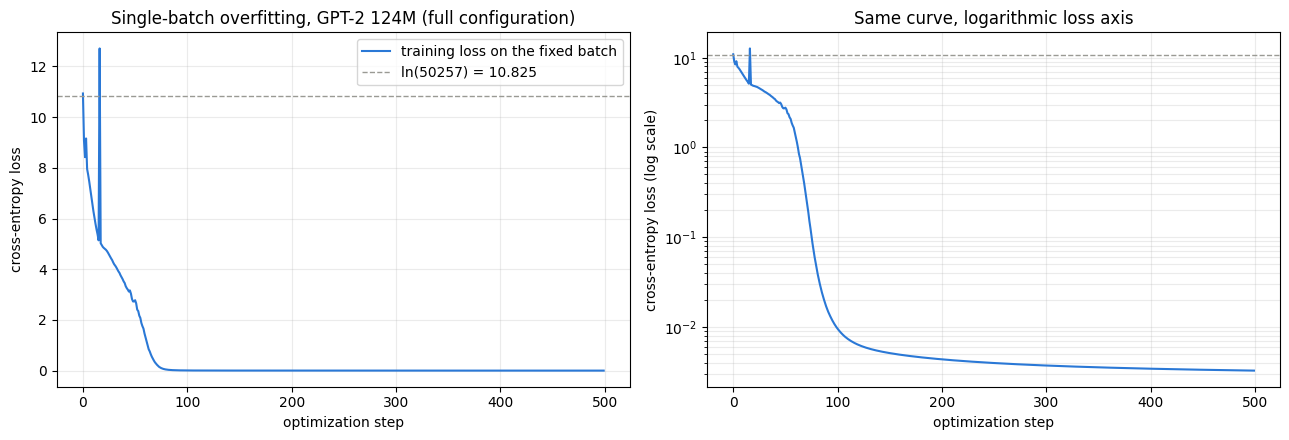

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, scale in zip(axes, ['linear', 'log']):
    ax.plot(range(len(losses)), losses, color='#2a78d6', linewidth=1.5, label='training loss on the fixed batch')
    ax.axhline(uniform_loss, color='#9a9a94', linestyle='--', linewidth=1, label='ln(50257) = 10.825')
    ax.set_yscale(scale)
    ax.set_xlabel('optimization step')
    ax.set_ylabel('cross-entropy loss' + (' (log scale)' if scale == 'log' else ''))
    ax.grid(alpha=0.25, which='both' if scale == 'log' else 'major')
axes[0].set_title(f'Single-batch overfitting, {config_name}')
axes[1].set_title('Same curve, logarithmic loss axis')
axes[0].legend()
plt.tight_layout()
plt.show()

In [48]:
assert len(losses) == overfit_steps
assert abs(losses[0] - initial_loss) < 1e-4 # same seed, same weights, same batch as the initial-loss measurement
assert losses[-1] < 0.1 * losses[0] # criterion fixed before the run
model.eval()
with torch.no_grad():
    _, final_eval_loss = model(x, y)
    batch_accuracy = (model(x)[0].argmax(-1) == y).float().mean().item()
print(f'loss after the last update: {final_eval_loss.item():.4f} | argmax predictions matching the targets: {batch_accuracy:.1%}')
print('Overfitting checks passed: the final loss is below 10% of the initial loss.')

# the same 20 windows used for the initial loss: text the model was not trained on
with torch.no_grad():
    other_losses = torch.stack([model(xs[k:k+B], ys[k:k+B])[1] for k in range(0, 20, B)])
print(f'loss on the 20 other windows: before training {window_losses.mean().item():.4f} | after memorizing the batch {other_losses.mean().item():.4f}')

loss after the last update: 0.0032 | argmax predictions matching the targets: 99.8%
Overfitting checks passed: the final loss is below 10% of the initial loss.
loss on the 20 other windows: before training 10.9772 | after memorizing the batch 10.8921


### Reading the Overfitting Curve

**Configuration.** The 10-step benchmark showed that the full GPT-2 124M configuration fits on the 6 GB RTX 3060 Laptop GPU with room to spare: peak allocated memory stayed under 3 GiB, and 500 steps were projected to take a little over a minute. The fallback configuration was therefore not needed. The run below used the **full 124,439,808-parameter model**, batch `(4, 128)`, AdamW at \(3\times10^{-4}\), float32 without TF32, for **500 steps**. The exact time per step, total time, and peak memory are printed above.

**The curve.** The loss starts at 10.9315, the value measured before training, which confirms that the run started from the same weights. It falls below 1.0 at step 62, below 0.1 at step 76, and below 0.01 at step 99, then decreases slowly to **0.0032** at step 500. After training, the model's argmax prediction matches 99.8% of the 512 targets (511 of 512). A loss of 0.0032 means an average log-probability of −0.0032 for the correct token, a geometric-mean probability of about 0.997. Reaching exactly zero would require infinite logits, and AdamW's weight decay pulls the weights slightly toward zero.

The curve is not monotonic. At step 16 the loss jumps from 5.14 to **12.71**, above the uniform loss, and recovers within a few steps; the benchmark run shows a smaller jump at step 3. The training loop has no learning-rate warmup and no gradient clipping, both of which the lecture introduces later for stability. Their absence may have contributed to the spike, but I did not isolate the cause experimentally, so other factors cannot be ruled out.

**Why this test is useful.** A model with 124M parameters can store far more than 512 target tokens, so a correct implementation should be able to memorize them, given reasonable optimization settings such as the learning rate and the number of steps. This run exercises every component together: the forward pass with its shifted targets and causal mask, the loss, gradients through all 12 blocks and both uses of the tied matrix, and the optimizer updates. If any of them were broken, the loss would stall or diverge instead of approaching zero. The test is cheap and needs no data pipeline, so it is worth running before longer training.

**What it does not show.** On 20 other windows of Tiny Shakespeare, the loss only moved from 10.977 before training to **10.892** after memorizing the batch. The model learned the 512 tokens it saw, not the language they come from. Memorizing one batch says nothing about generalization; that requires training on the whole corpus and measuring loss on held-out text, which is the next part of the lecture.

## Final Notes

- **Pretrained GPT-2.** GPT-2 small has 12 blocks, 12 heads, 768 channels, a 1,024-token context, a 50,257-token vocabulary, and **124,439,808 unique parameters**. The state dict lists 149 tensors and 163,037,184 numbers because `wte` and `lm_head` share one matrix. The learned position embeddings are smooth across nearby positions, with an oscillating, sinusoid-like similarity structure, channel-level noise, a large vector at position 0, and an almost-zero vector at position 1023.
- **My implementation.** Starting from my Week 8 GPT, the main changes are:
  - a fused `c_attn` projection with biases for the queries, keys, and values of all heads;
  - GELU with the tanh approximation instead of ReLU;
  - no bias in `lm_head`, and weight tying with `wte`;
  - GPT-2's scale and BPE vocabulary.

  Loading the Hugging Face weights requires transposing the 48 Conv1D projection weights, because Conv1D stores `(in, out)` and `nn.Linear` stores `(out, in)`.
- **Verification.** All 149 tensors load exactly. On the same input, the logits agree with a maximum absolute difference of 7.8e-04 and a mean of 3.0e-05. The comparison passes `allclose(atol=1e-4, rtol=1e-5)` and gives identical argmax tokens and losses. The per-block comparison places the remaining differences at float32 rounding. My greedy generation matches Hugging Face's token for token.
- **Generation.** With top-k sampling (\(k=50\)), GPT-2 writes locally fluent, web-like English that drifts off topic and invents facts. Its Turkish continuations are not grammatical Turkish: they mix invented words, foreign letters, and English.
- **Tokenization.** GPT-2's tokenizer needs 360 tokens for the Week 9 Turkish paragraph, against 296 for `cl100k_base`. For the English translation, both need 188. On the Turkish held-out text it reaches 2.16 bytes per token, no better than my 512-token Turkish tokenizers. GPT-2's poor Turkish comes mainly from its English-dominated training data; fragmentation adds to the cost.
- **Training from scratch.** A randomly initialized GPT-2 starts at a loss of 10.93 on the fixed batch and 10.98 on random windows, against \(\ln 50257=10.82\) for a uniform guess and the predicted \(\ln V+\sigma^2/2=10.98\). The full 124M model overfits one `(4, 128)` batch from 10.93 to 0.0032 in 500 steps on the RTX 3060 Laptop GPU, while its loss on other text barely changes.

## Limitations

- **Few prompts:** two English and two Turkish prompts, four samples each, with one temperature, one \(k\), and one seed per prompt. The observations about fluency and Turkish quality are qualitative; I did not measure GPT-2's loss on Turkish and English sentences.
- **Language comparison:** one translated paragraph pair and one held-out Turkish text from a single literary corpus. The Week 9 tokenizer rows are saved values, not recomputed. The tokenizers differ in vocabulary size and training data at the same time.
- **Verification scope:** the logit comparison uses one `(4, 64)` input of Shakespeare text and one GPU. Longer contexts, other inputs, and CPU execution were not compared. Agreement is within float32 rounding, not bit-exact.
- **No pretraining:** I trained only on one fixed batch for 500 steps; there is no data loader, no full-corpus training, and no held-out evaluation. The loss spike at step 16 was not investigated, and learning-rate warmup and gradient clipping were not used.
- **Hardware:** all runs used one RTX 3060 Laptop GPU with 6 GB, in float32 without TF32 and without `torch.compile` (Triton is not installed on this Windows environment). Times and memory figures depend on this machine and on what else was running.
- **Not attempted:** the optional Task 5 bonus, (a) full-text training or (b) Turkish versus English loss, is not part of this notebook.